---
title: "TP Statistiques Spatiales"
author: "Niels Saura"
date: today
format:
  html:
    theme: cosmo
    toc: true
    code-fold: true
    embed-resources: true
jupyter: python3
---

# TP Statistiques Spatiales
Notebook présentant des TP du master IGAST dont les énoncés ont été créés par Martin Cubaud ([sujet1](https://www.umr-lastig.fr/martin-cubaud/cours/TP3_analyse_multivariee/support_TP3.pdf), [sujet2](https://www.umr-lastig.fr/martin-cubaud/cours/TP4_regression_multivariee/sujet_TP4.pdf)).  
Ce TP s'appuie sur des données ayant pour unité d'étude les états nations et issues de [ourworldindata](https://www.ourworldindata.org) :

- Le PIB par habitant
- La part du revenu national concentrée par les 1% les plus riches, les 9% suivants, les 40% suivants et les 50% les plus pauvres
- Le nombre moyen d'années de scolarisation
- La part du PIB consacrée à la recherche

Ce notebook explore ce jeu de données via des outils paradigmatiques des statistiques spatiales : l'analyse en composante principale ; la classification ascendante hiérarchique ; la régression linéaire multiple ; l'auto-corrélation spatiale fondée sur un voisinnage déterminé par triangulation de Delaunay ; la régression multiple pondérée géographiquement.

In [134]:
#imports
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from os.path import join
import os
import osmnx
import glob
from sklearn.decomposition import PCA
import networkx as nx
from scipy.spatial import Delaunay
from geopy.distance import geodesic
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

# construction du geodataframe à partir des données ourworldindata
geo_countries=gpd.read_file(r".\geo-countries\data\countries.geojson")
gdp_per_capita=pd.read_csv(r".\ourworldindata\gdp-per-capita-worldbank.filtered\gdp-per-capita-worldbank.csv")
income_distribution=pd.read_csv(r".\ourworldindata\incomes-of-the-richest\distribution-of-income-across-richer-and-poorer-groups-before-tax.csv")
income_distribution2022=income_distribution[income_distribution.Year==2022]
schooling_mean_years=pd.read_csv(r".\ourworldindata\mean-years-of-schooling-long-run.filtered\mean-years-of-schooling-long-run.csv")
research_spending=pd.read_csv(r".\ourworldindata\research-spending-gdp.filtered\research-spending-gdp.csv")
research_spending_mean=research_spending.groupby("Entity")[r"Research and development expenditure (% of GDP)"].mean()
research_spending_mean=pd.DataFrame(research_spending_mean).reset_index()
all_vars=pd.merge(gdp_per_capita, income_distribution2022.drop(columns=["Code", "Year"]), on="Entity").merge(schooling_mean_years.drop(columns=["Code", "Year"]), on="Entity").merge(research_spending_mean, on="Entity")
country_gdf=osmnx.geocode_to_gdf(all_vars.Entity.tolist())
all_vars=all_vars.join(country_gdf[["geometry", "lat", "lon"]])
all_vars.drop(columns="GDP per capita (Original Year)", inplace=True)
all_vars=gpd.GeoDataFrame(all_vars, crs=4326, geometry="geometry")

# Cartes choroplèthes des différentes variables

In [135]:
xmin, ymin, xmax, ymax=geo_countries.total_bounds
map_width=xmax-xmin
map_height=ymax-ymin
map_relative_width=map_width/map_height

Text(0.5, 1.0, 'GDP per capita')

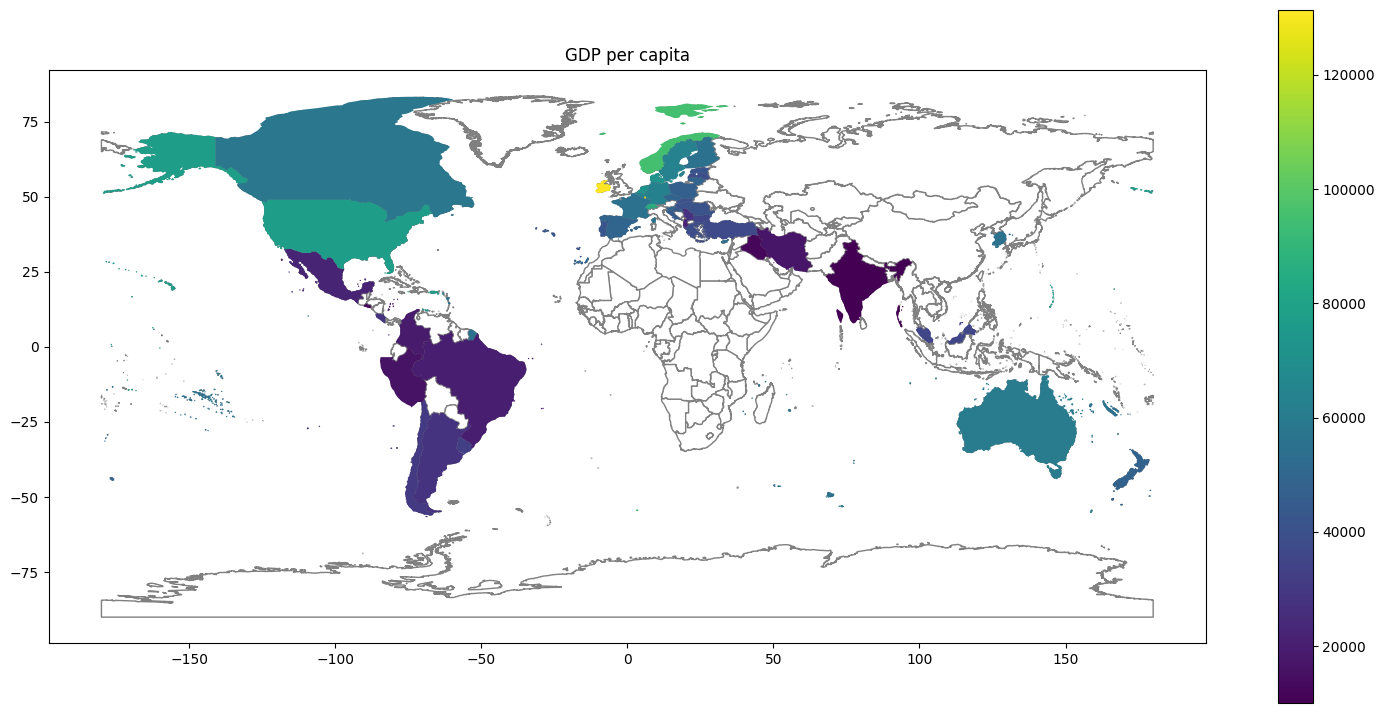

In [136]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="GDP per capita",
    legend=True
)
ax.set_title("GDP per capita")

Text(0.5, 1.0, 'Richest 1% income share')

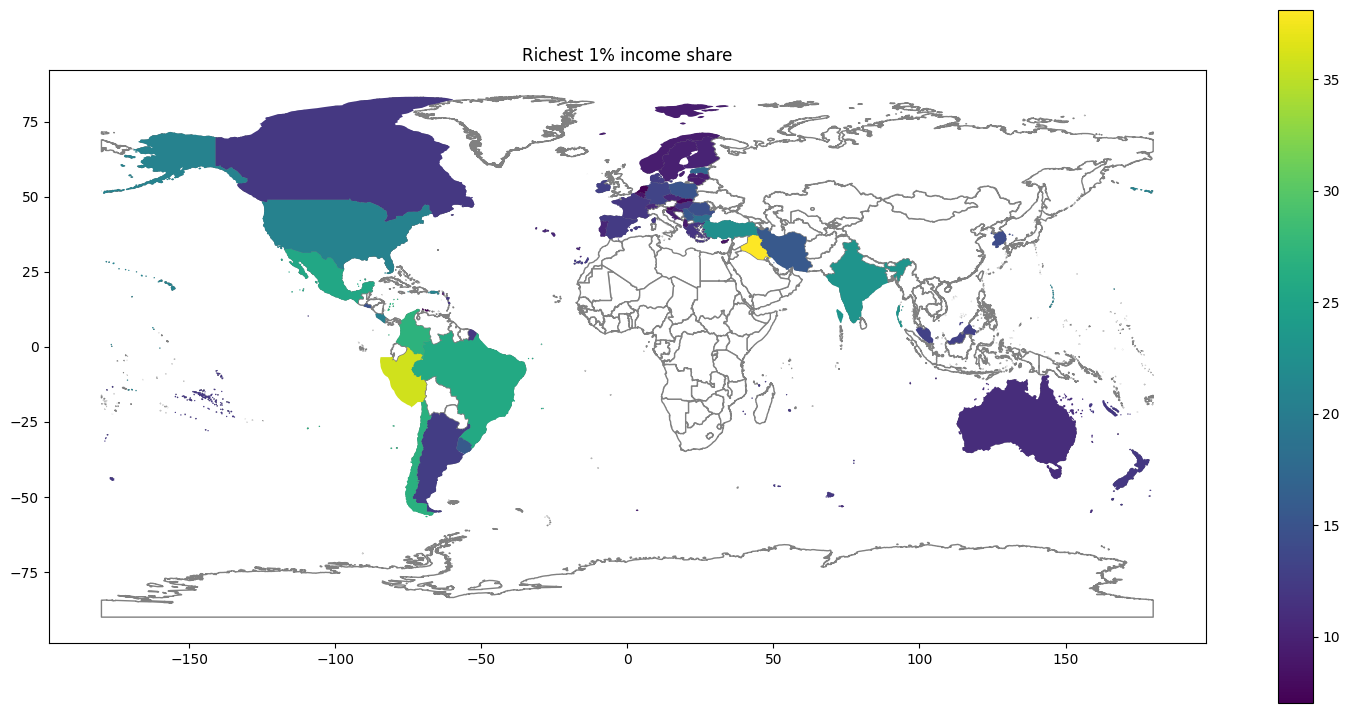

In [137]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="Richest 1%",
    legend=True
    )
ax.set_title(r"Richest 1% income share")

Text(0.5, 1.0, 'Next 9% income share')

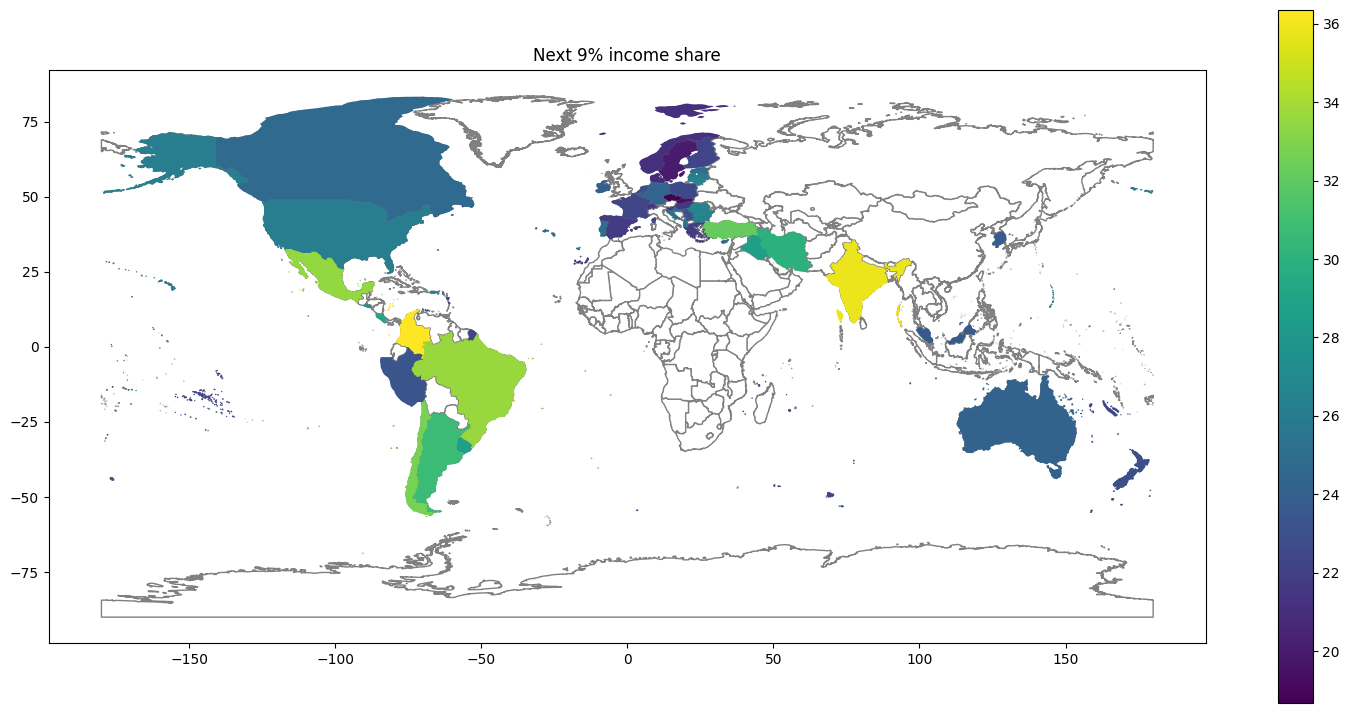

In [138]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="Next 9%",
    legend=True
)
ax.set_title(r"Next 9% income share")

Text(0.5, 1.0, 'Middle 40% income share')

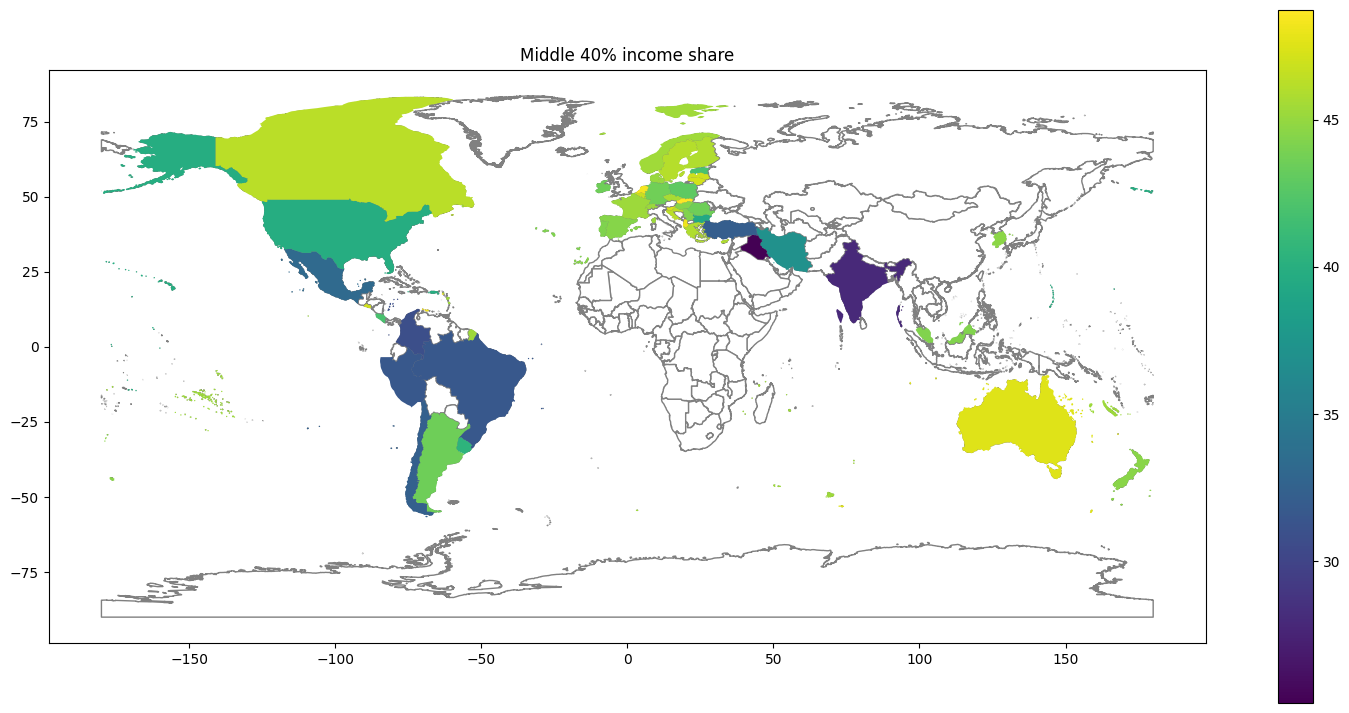

In [139]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="Middle 40%",
    legend=True
)
ax.set_title(r"Middle 40% income share")

Text(0.5, 1.0, 'Poorest 50% income share')

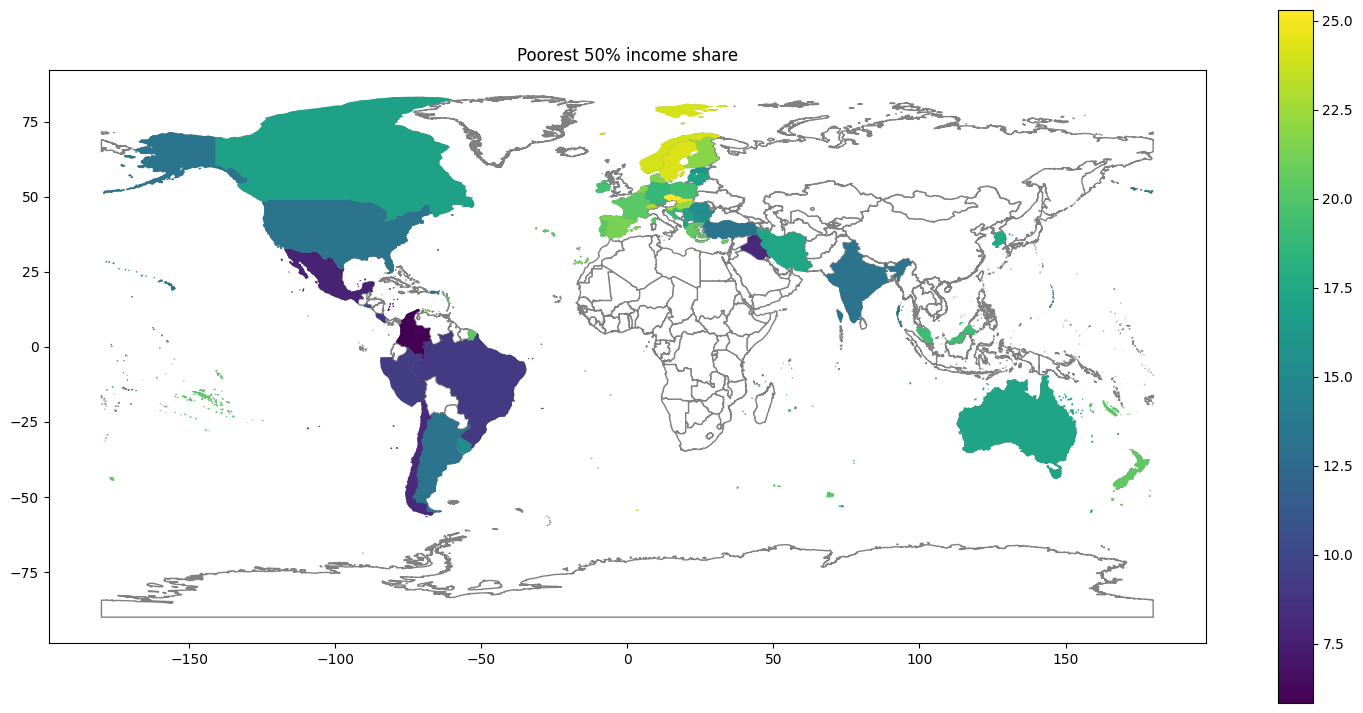

In [140]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="Poorest 50%",
    legend=True
)
ax.set_title(r"Poorest 50% income share")

Text(0.5, 1.0, 'Average years of schooling')

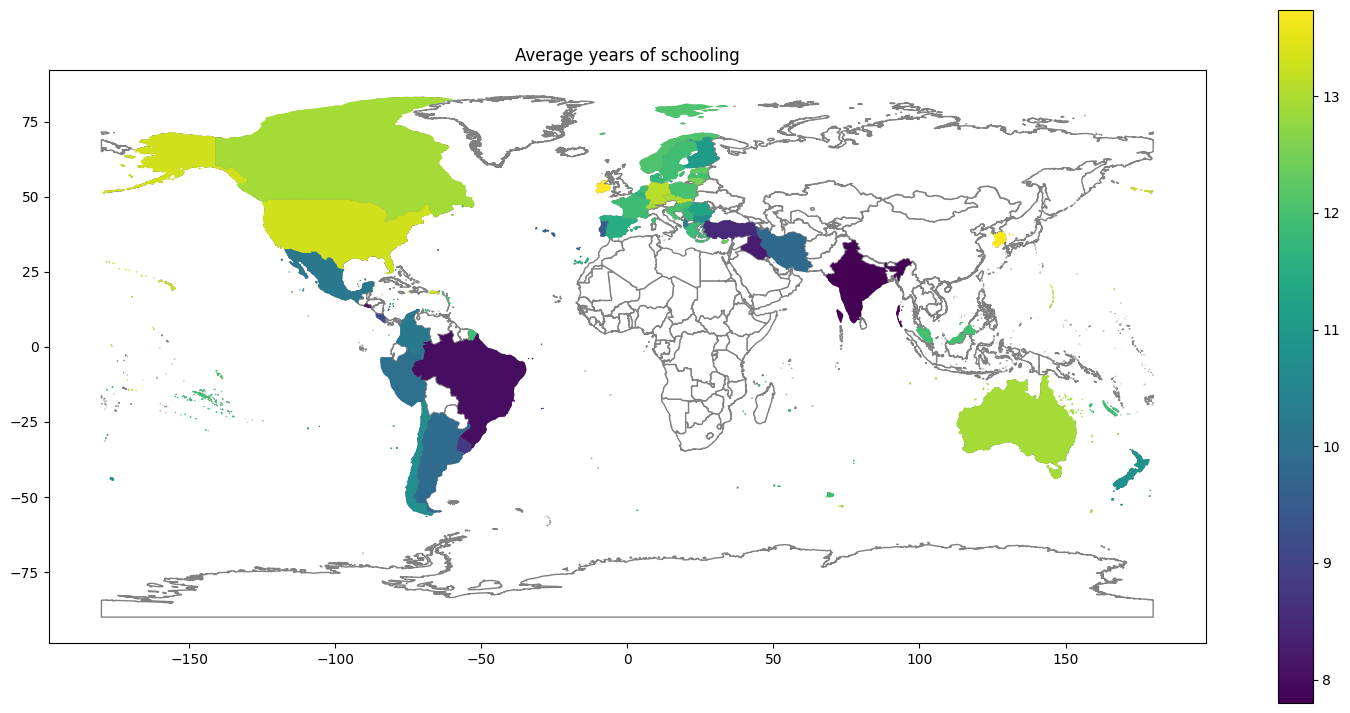

In [141]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="Average years of schooling",
    legend=True
)
ax.set_title(r"Average years of schooling")

Text(0.5, 1.0, 'Research and development expenditure (% of GDP)')

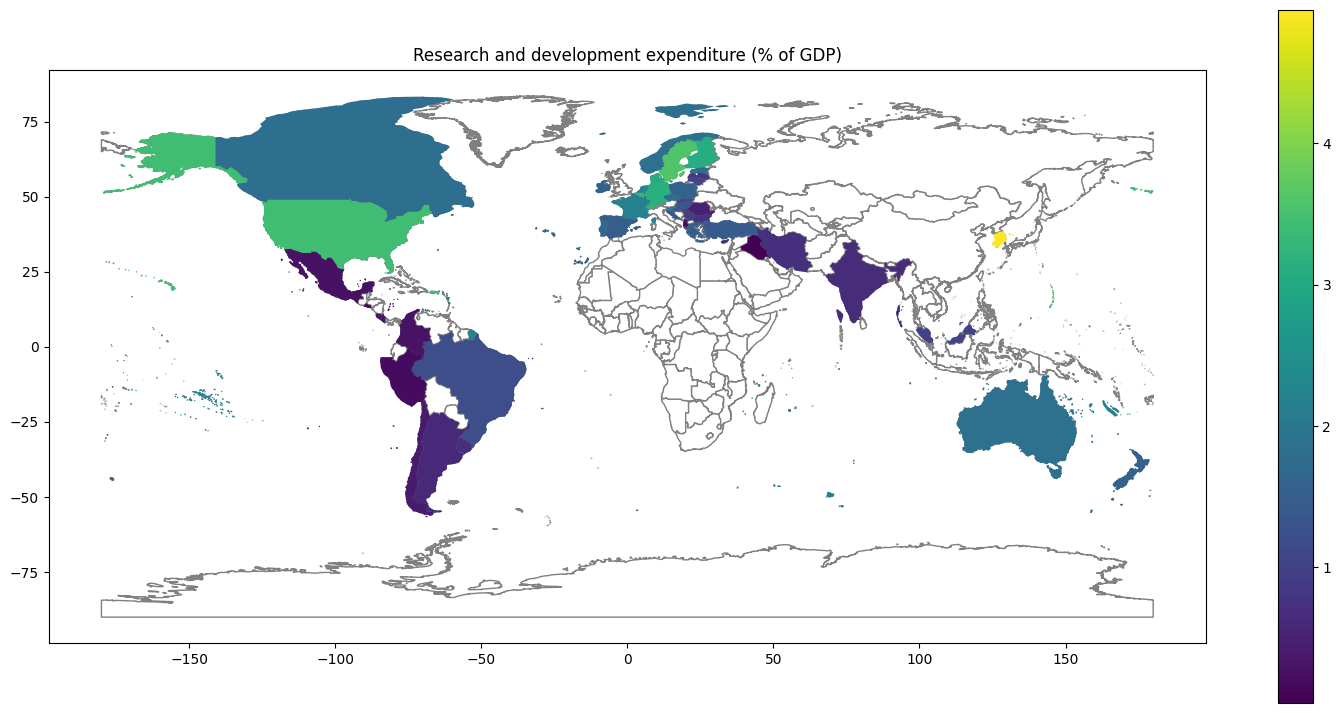

In [142]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="Research and development expenditure (% of GDP)",
    legend=True
)
ax.set_title(r"Research and development expenditure (% of GDP)")

# Description et corrélations des différentes variables explicatives

In [143]:
all_vars.describe()

,Year,GDP per capita,Richest 1%,Next 9%,Middle 40%,Poorest 50%,Average years of schooling,Research and development expenditure (% of GDP),lat,lon
count,47.0,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000
mean,2025.0,47131.971213,14.974468,25.422128,42.337447,17.264468,11.246383,1.503678,32.236487,5.806554
std,0.0,26193.730219,7.067727,4.295438,5.951559,5.060054,1.595727,1.100194,28.676239,60.386287
min,2025.0,10039.071000,7.040000,18.680000,25.180000,5.840000,7.800000,0.040700,-41.500083,-107.991707
25%,2025.0,29653.417000,10.160000,22.430000,41.145001,14.295000,10.190000,0.691705,23.004813,-8.057406
50%,2025.0,42576.812000,12.520000,24.360000,44.420002,17.630000,11.720000,1.386210,42.607397,14.815333
75%,2025.0,56862.400000,16.520000,27.145001,46.099999,20.680000,12.185000,1.854625,50.902049,25.042836
max,2025.0,131338.440000,38.100000,36.350000,48.730000,25.300000,13.740000,4.943520,63.246778,172.834408


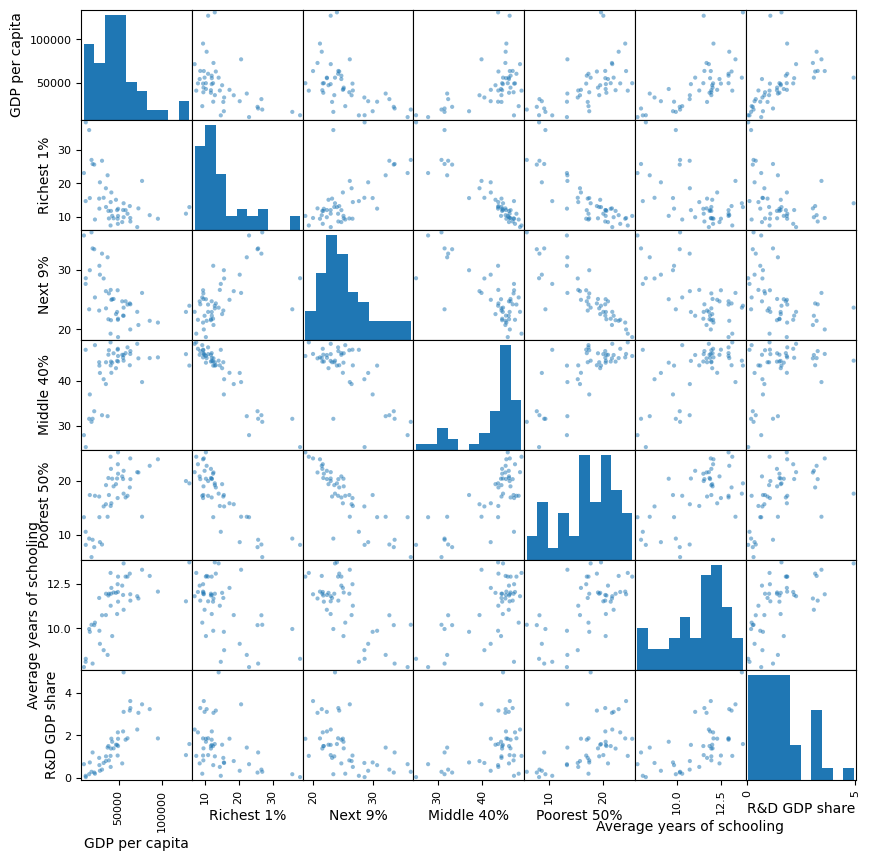

In [144]:
fig, ax=plt.subplots(figsize=(10,10))
_=pd.plotting.scatter_matrix(all_vars.drop(columns=["Year", "lat", "lon"]).rename(columns={r"Research and development expenditure (% of GDP)":"R&D GDP share"}), ax=ax)

Corrélations des différentes variables explicatives

In [145]:
vars_arr=all_vars.drop(columns=["Entity", "Code", "Year", "World region according to OWID", "geometry", "lat", "lon"]).values
vars_cr=(vars_arr-vars_arr.mean(axis=0))/vars_arr.std(axis=0)
corr_matrix=(vars_cr.T@vars_cr)/len(vars_cr)
corr_df=pd.DataFrame(corr_matrix, index=all_vars.drop(columns=["Entity", "Code", "Year", "World region according to OWID", "geometry", "lat", "lon"]).columns, columns=all_vars.drop(columns=["Entity", "Code", "Year", "World region according to OWID", "geometry", "lat", "lon"]).columns)
corr_df.round(2).style.format("{:.2f}").background_gradient()

,GDP per capita,Richest 1%,Next 9%,Middle 40%,Poorest 50%,Average years of schooling,Research and development expenditure (% of GDP)
GDP per capita,1.00,-0.49,-0.53,0.48,0.57,0.65,0.55
Richest 1%,-0.49,1.00,0.63,-0.93,-0.84,-0.57,-0.42
Next 9%,-0.53,0.63,1.00,-0.75,-0.85,-0.68,-0.51
Middle 40%,0.48,-0.93,-0.75,1.00,0.75,0.64,0.40
Poorest 50%,0.57,-0.84,-0.85,0.75,1.00,0.63,0.54
Average years of schooling,0.65,-0.57,-0.68,0.64,0.63,1.00,0.58
Research and development expenditure (% of GDP),0.55,-0.42,-0.51,0.40,0.54,0.58,1.00


# Analyse en Composantes Principales

In [146]:
vars_cr_df=pd.DataFrame(vars_cr, columns=all_vars.drop(columns=["Entity", "Code", "Year", "World region according to OWID", "geometry", "lat", "lon"]).columns)
pca=PCA()
_=pca.fit(vars_cr_df)

Calcul de la corrélation entre chaque cp et chaque variable.  

On a $Corr(Y, X_i)=\frac{Cov(Y, X_i)}{\sigma _Y\times \sigma _{X_i}}$. Avec Y, les données projetées sur la CP et $X_i$ une variable explicative.  
Notre jeu de données étant centré et réduit, $\sigma _{X_i}=1$. La variance projetée est la valeur propre $\lambda$ de la cp.  
Enfin, $Y=Xu$ avec u la cp, vecteur unitaire exprimé dans le système de coordonnées formé par les variables explicatives.  
D'où $Cov(Y, X_i)=Cov(Xu, X_i)=(covariance matrix\times u)_i$, ce qui vaut $\lambda u$, puisque u est un vecteur propre de la matrice de covariance.  
D'où $Corr(Y, X_i)=\frac{Cov(Y, X_i)}{\sigma _Y\times \sigma _{X_i}}=\frac{\lambda u_i}{\sqrt{\lambda}}=\sqrt{\lambda}\times u_i$.

In [147]:
cp_vars_corrs=pca.components_*np.sqrt(pca.explained_variance_)[:,np.newaxis]
cp_vars_corrs_df=pd.DataFrame(cp_vars_corrs, columns=all_vars.drop(columns=["Entity", "Code", "Year", "World region according to OWID", "geometry", "lat", "lon"]).columns)
cp_vars_corrs_df.round(2).style.format("{:.2f}").background_gradient(axis=1)

,GDP per capita,Richest 1%,Next 9%,Middle 40%,Poorest 50%,Average years of schooling,Research and development expenditure (% of GDP)
0,0.73,-0.87,-0.88,0.88,0.92,0.83,0.68
1,0.44,0.40,0.08,-0.39,-0.17,0.26,0.55
2,0.46,-0.03,0.13,0.06,-0.14,0.17,-0.44
3,0.14,-0.31,0.42,0.10,-0.05,-0.25,0.22
4,-0.24,-0.06,0.17,0.16,-0.26,0.39,0.06
5,-0.06,-0.09,0.16,-0.22,0.24,0.14,-0.06
6,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00


In [148]:
vars_pcaed=pca.transform(vars_cr_df)
pcaed_gdf=all_vars[["geometry", "Entity"]].join(pd.DataFrame(vars_pcaed))
map_relative_height=map_height/map_width
cp_vars_corrs_df.columns
cp_vars_corrs_df.rename(columns={'Research and development expenditure (% of GDP)':"R&D GDP shape"}, inplace=True)

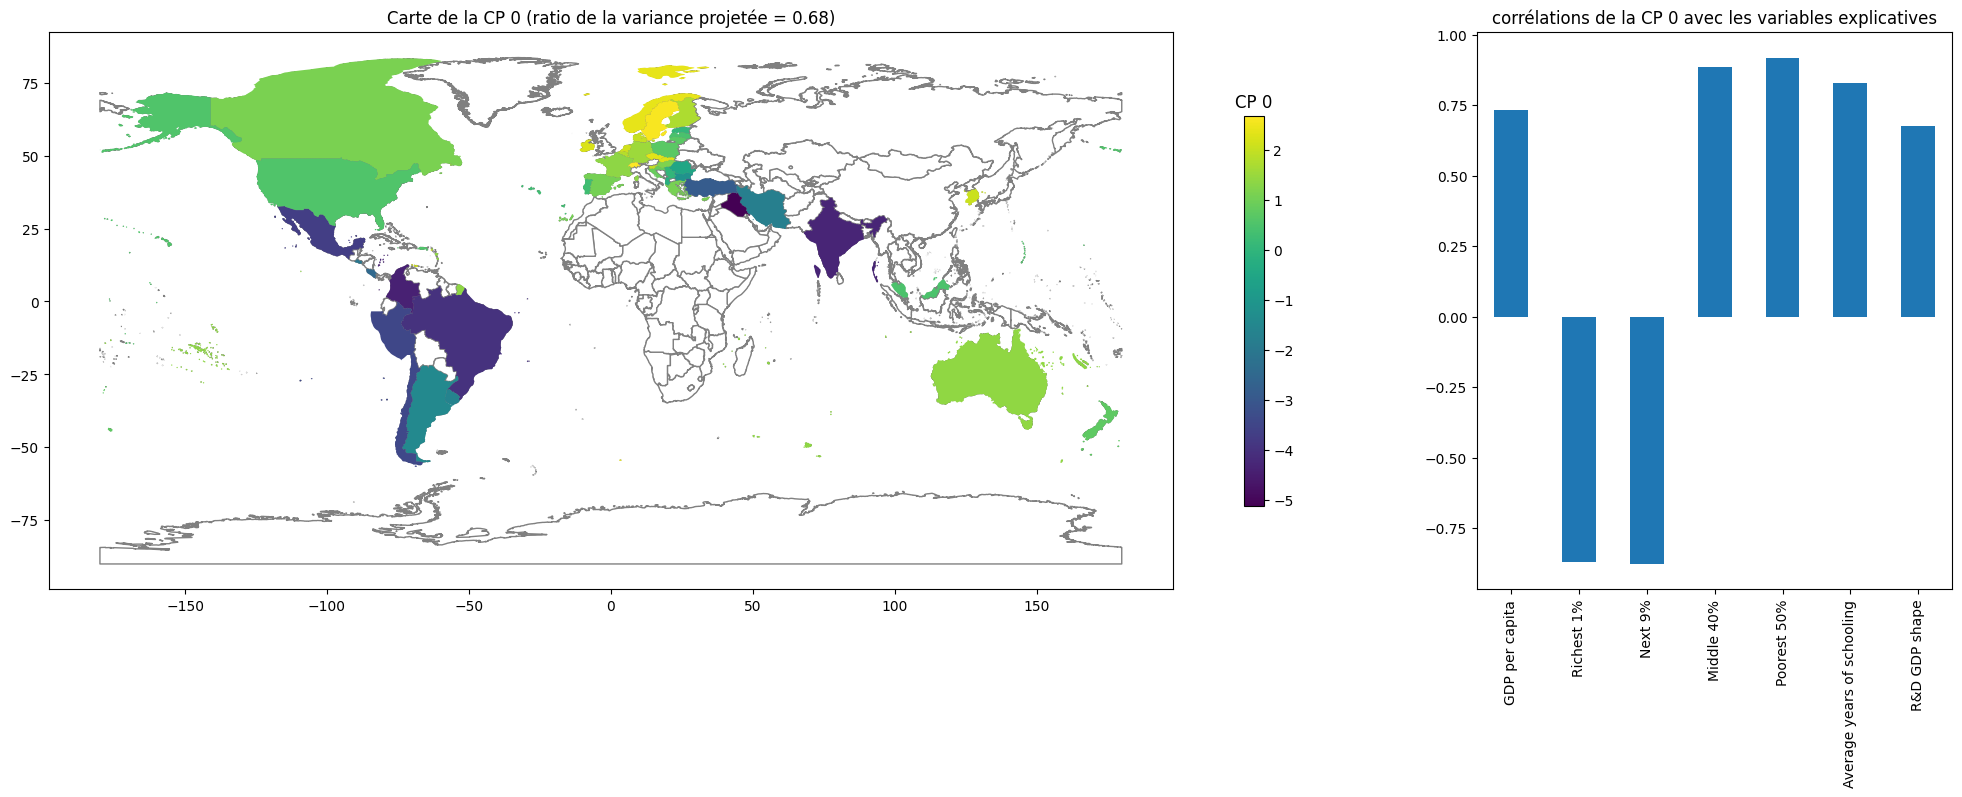

In [149]:
cp = 0
width_ratio = (3, 1)
width = 20
scale_factor = 9

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(
        width,
        (width_ratio[0] / sum(width_ratio)) * width * map_relative_height
    ),
    gridspec_kw={
        "width_ratios": width_ratio,
        "wspace": 0.02
    }
)

geo_countries.plot(
    ax=ax1,
    color="white",
    edgecolor="gray"
)

pcaed_gdf.plot(
    ax=ax1,
    column=cp,
    legend=True,
    legend_kwds={"shrink": 0.7}
)

ax1.get_figure().axes[-1].set_title(f"CP {cp}")

cp_vars_corrs_df.loc[cp].plot.bar(ax=ax2)
ax1.set_title(f"Carte de la CP {cp} (ratio de la variance projetée = {np.round(pca.explained_variance_ratio_[cp], 2)})")
ax2.set_title(f"corrélations de la CP {cp} avec les variables explicatives")

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.show()

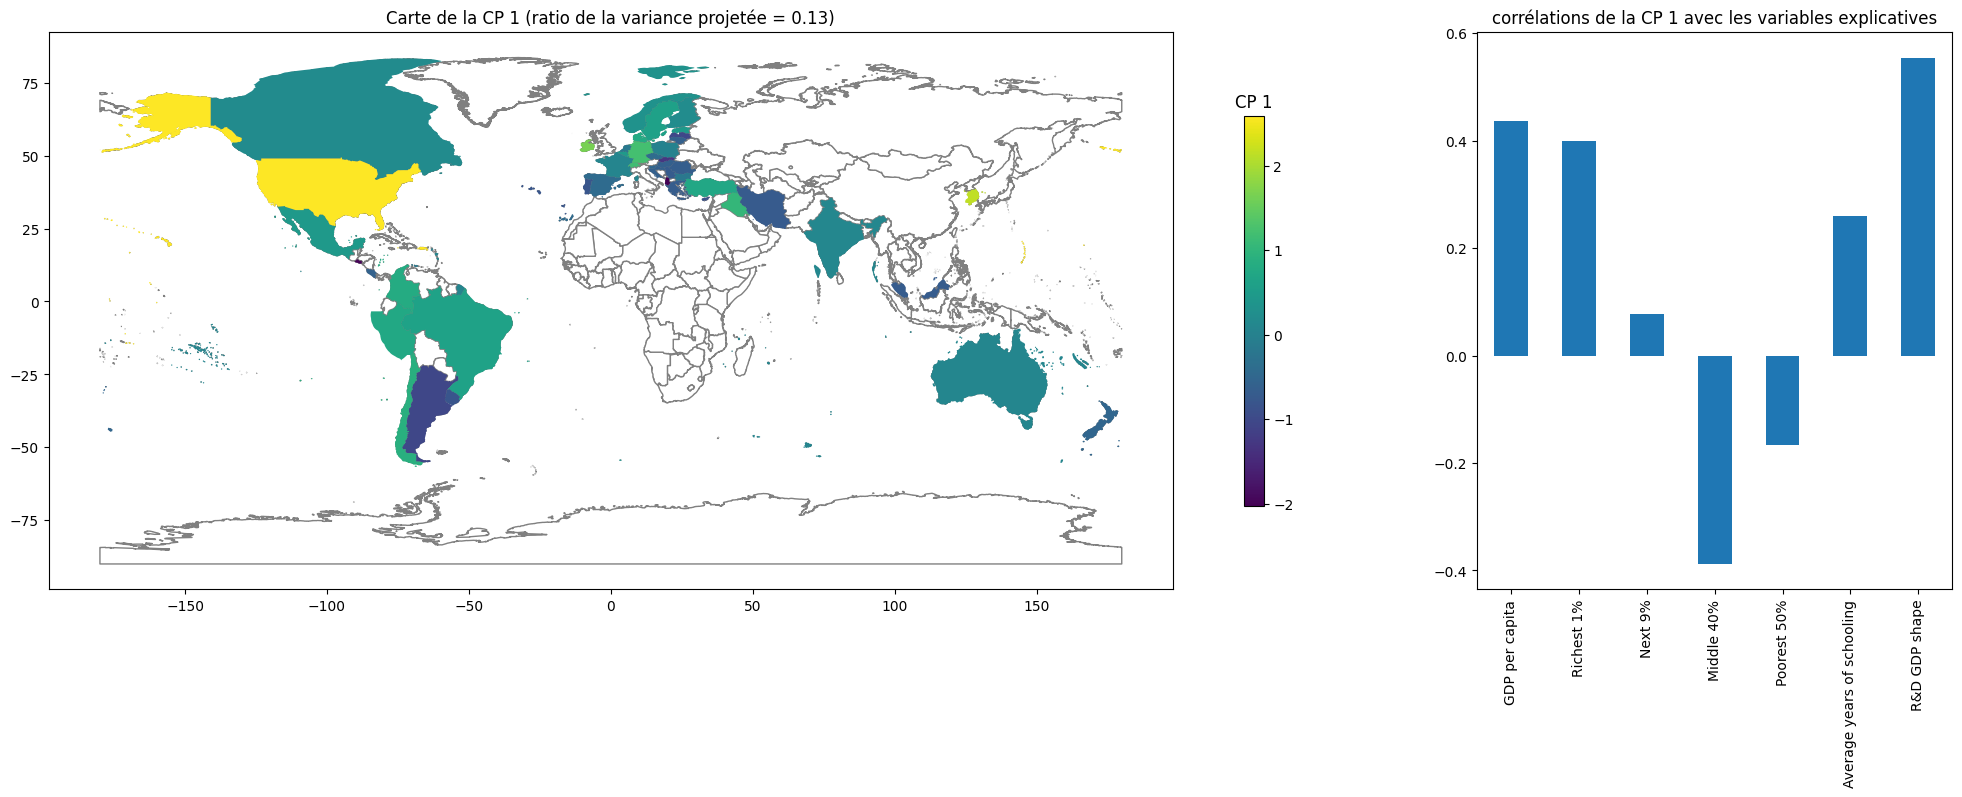

In [150]:
cp = 1
width_ratio = (3, 1)
width = 20
scale_factor = 9

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(
        width,
        (width_ratio[0] / sum(width_ratio)) * width * map_relative_height
    ),
    gridspec_kw={
        "width_ratios": width_ratio,
        "wspace": 0.02
    }
)

geo_countries.plot(
    ax=ax1,
    color="white",
    edgecolor="gray"
)

pcaed_gdf.plot(
    ax=ax1,
    column=cp,
    legend=True,
    legend_kwds={"shrink": 0.7}
)

ax1.get_figure().axes[-1].set_title(f"CP {cp}")

cp_vars_corrs_df.loc[cp].plot.bar(ax=ax2)

ax1.set_title(f"Carte de la CP {cp} (ratio de la variance projetée = {np.round(pca.explained_variance_ratio_[cp], 2)})")
ax2.set_title(f"corrélations de la CP {cp} avec les variables explicatives")

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.show()

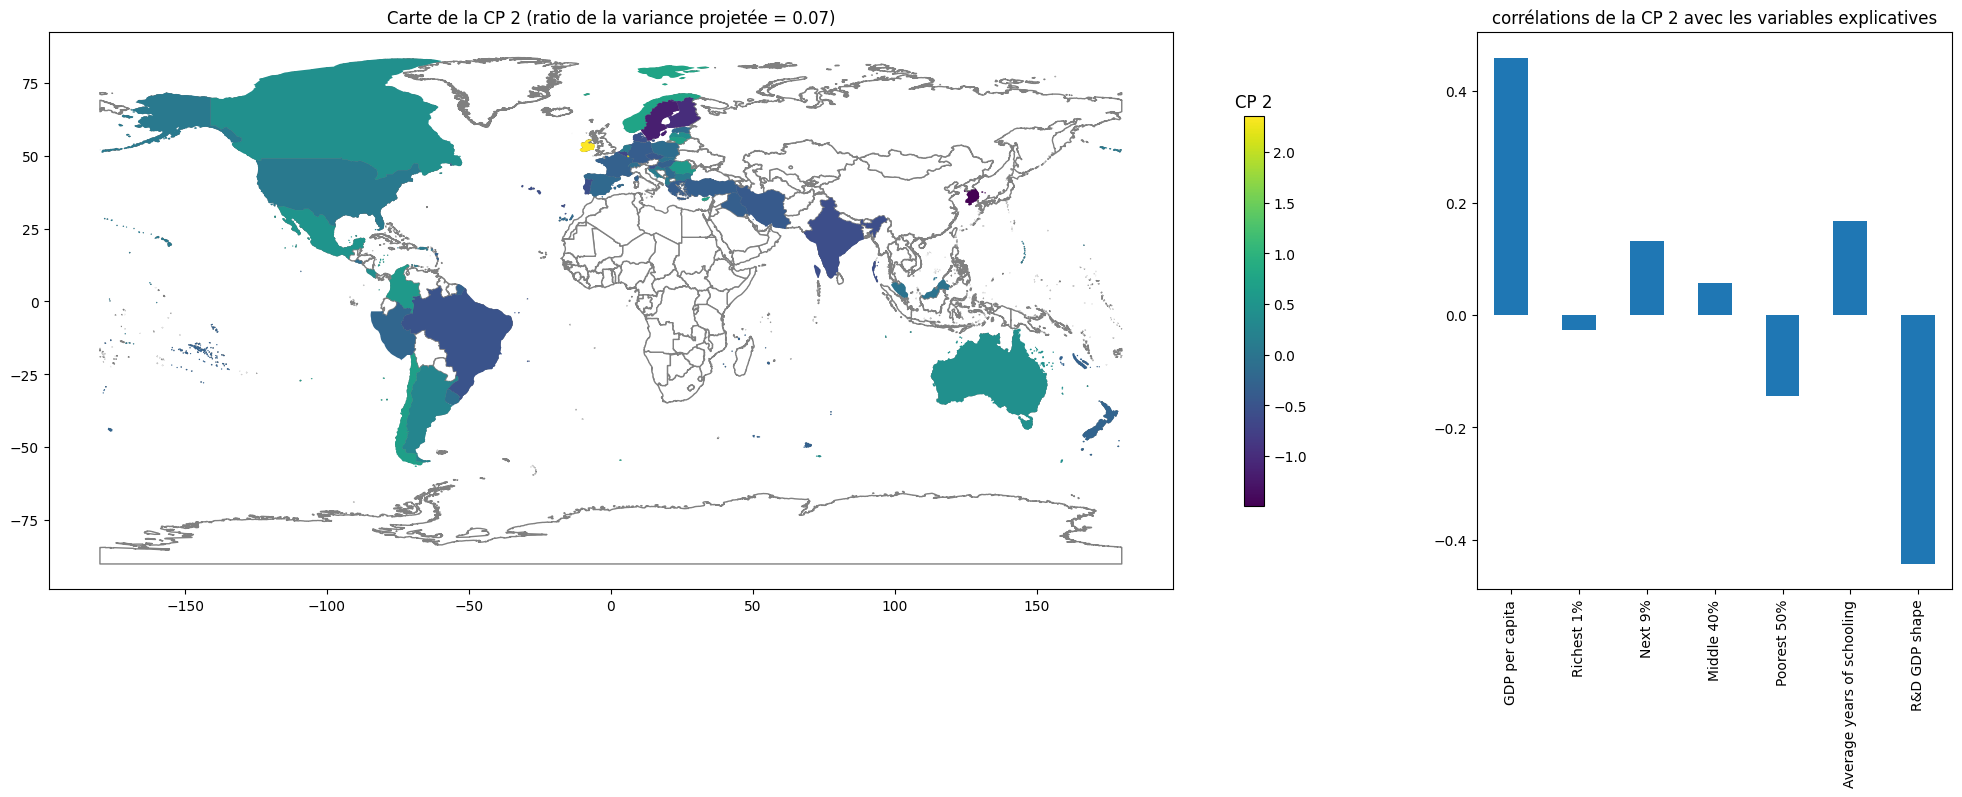

In [151]:
cp = 2
width_ratio = (3, 1)
width = 20
scale_factor = 9

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(
        width,
        (width_ratio[0] / sum(width_ratio)) * width * map_relative_height
    ),
    gridspec_kw={
        "width_ratios": width_ratio,
        "wspace": 0.02
    }
)

geo_countries.plot(
    ax=ax1,
    color="white",
    edgecolor="gray"
)

pcaed_gdf.plot(
    ax=ax1,
    column=cp,
    legend=True,
    legend_kwds={"shrink": 0.7}
)

ax1.get_figure().axes[-1].set_title(f"CP {cp}")

cp_vars_corrs_df.loc[cp].plot.bar(ax=ax2)

ax1.set_title(f"Carte de la CP {cp} (ratio de la variance projetée = {np.round(pca.explained_variance_ratio_[cp], 2)})")
ax2.set_title(f"corrélations de la CP {cp} avec les variables explicatives")

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.show()

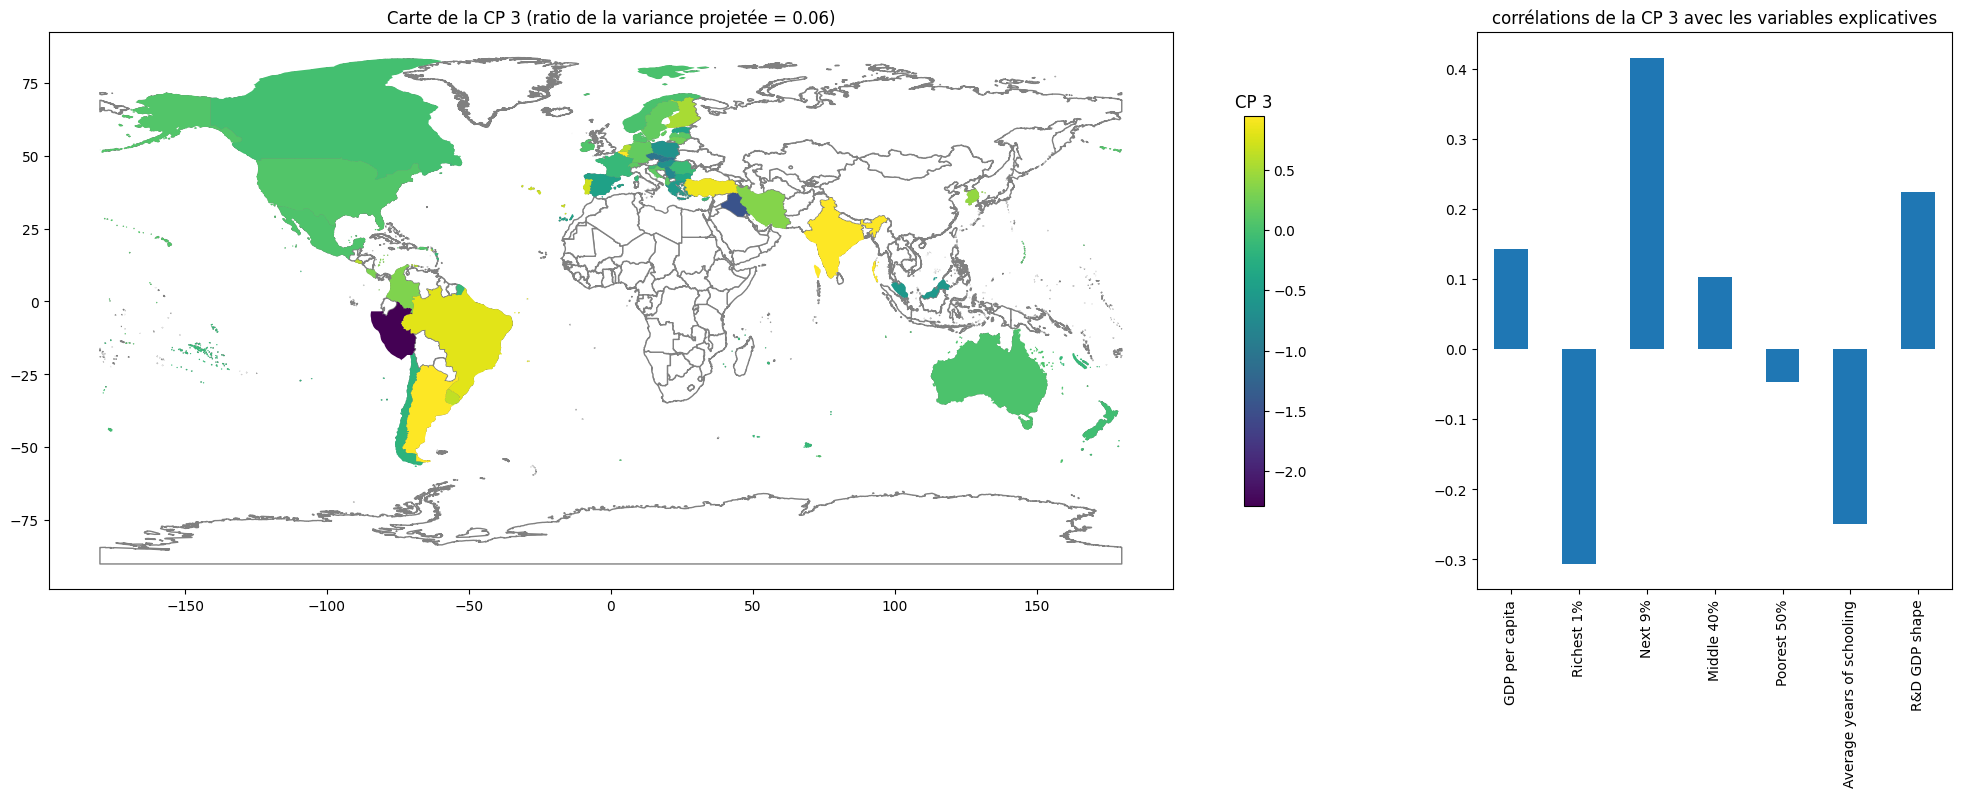

In [152]:
cp = 3
width_ratio = (3, 1)
width = 20
scale_factor = 9

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(
        width,
        (width_ratio[0] / sum(width_ratio)) * width * map_relative_height
    ),
    gridspec_kw={
        "width_ratios": width_ratio,
        "wspace": 0.02
    }
)

geo_countries.plot(
    ax=ax1,
    color="white",
    edgecolor="gray"
)

pcaed_gdf.plot(
    ax=ax1,
    column=cp,
    legend=True,
    legend_kwds={"shrink": 0.7}
)

ax1.get_figure().axes[-1].set_title(f"CP {cp}")

cp_vars_corrs_df.loc[cp].plot.bar(ax=ax2)

ax1.set_title(f"Carte de la CP {cp} (ratio de la variance projetée = {np.round(pca.explained_variance_ratio_[cp], 2)})")
ax2.set_title(f"corrélations de la CP {cp} avec les variables explicatives")

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.show()

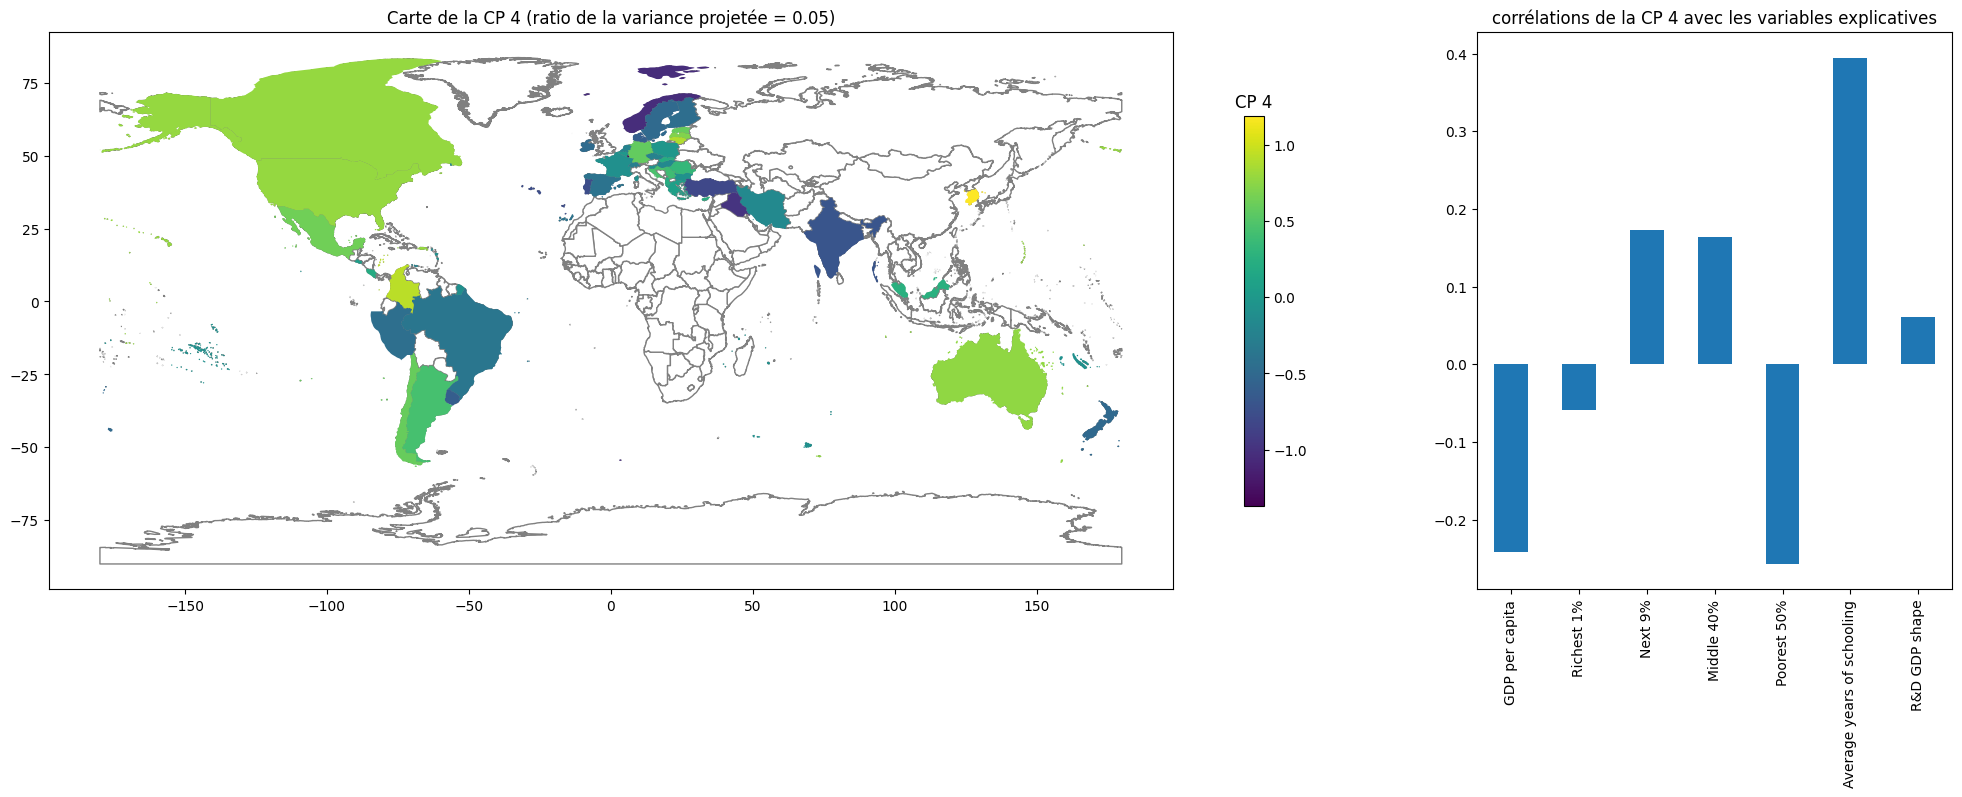

In [153]:
cp = 4
width_ratio = (3, 1)
width = 20
scale_factor = 9

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(
        width,
        (width_ratio[0] / sum(width_ratio)) * width * map_relative_height
    ),
    gridspec_kw={
        "width_ratios": width_ratio,
        "wspace": 0.02
    }
)

geo_countries.plot(
    ax=ax1,
    color="white",
    edgecolor="gray"
)

pcaed_gdf.plot(
    ax=ax1,
    column=cp,
    legend=True,
    legend_kwds={"shrink": 0.7}
)

ax1.get_figure().axes[-1].set_title(f"CP {cp}")

cp_vars_corrs_df.loc[cp].plot.bar(ax=ax2)
ax1.set_title(f"Carte de la CP {cp} (ratio de la variance projetée = {np.round(pca.explained_variance_ratio_[cp], 2)})")
ax2.set_title(f"corrélations de la CP {cp} avec les variables explicatives")

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.show()

# Classification Ascendante hiérarchique et dendrogramme

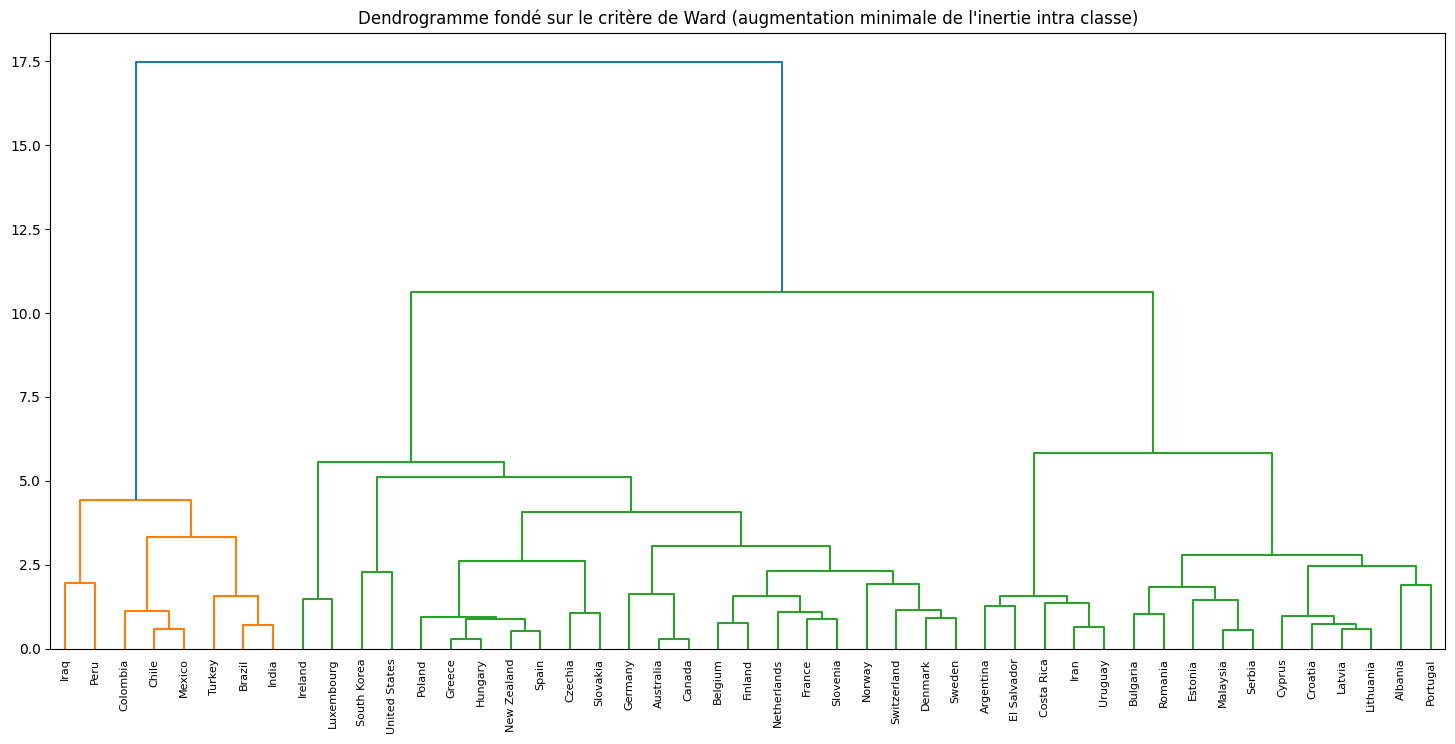

In [154]:
df_for_dendrogram=pcaed_gdf.drop(columns=["geometry"]).set_index("Entity")[[0, 1, 2, 3, 4]]
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(df_for_dendrogram, 'ward')
plt.figure(figsize=(18, 8))
dn = dendrogram(Z, labels=df_for_dendrogram.index.tolist())
plt.title("Dendrogramme fondé sur le critère de Ward (augmentation minimale de l'inertie intra classe)")
plt.show()

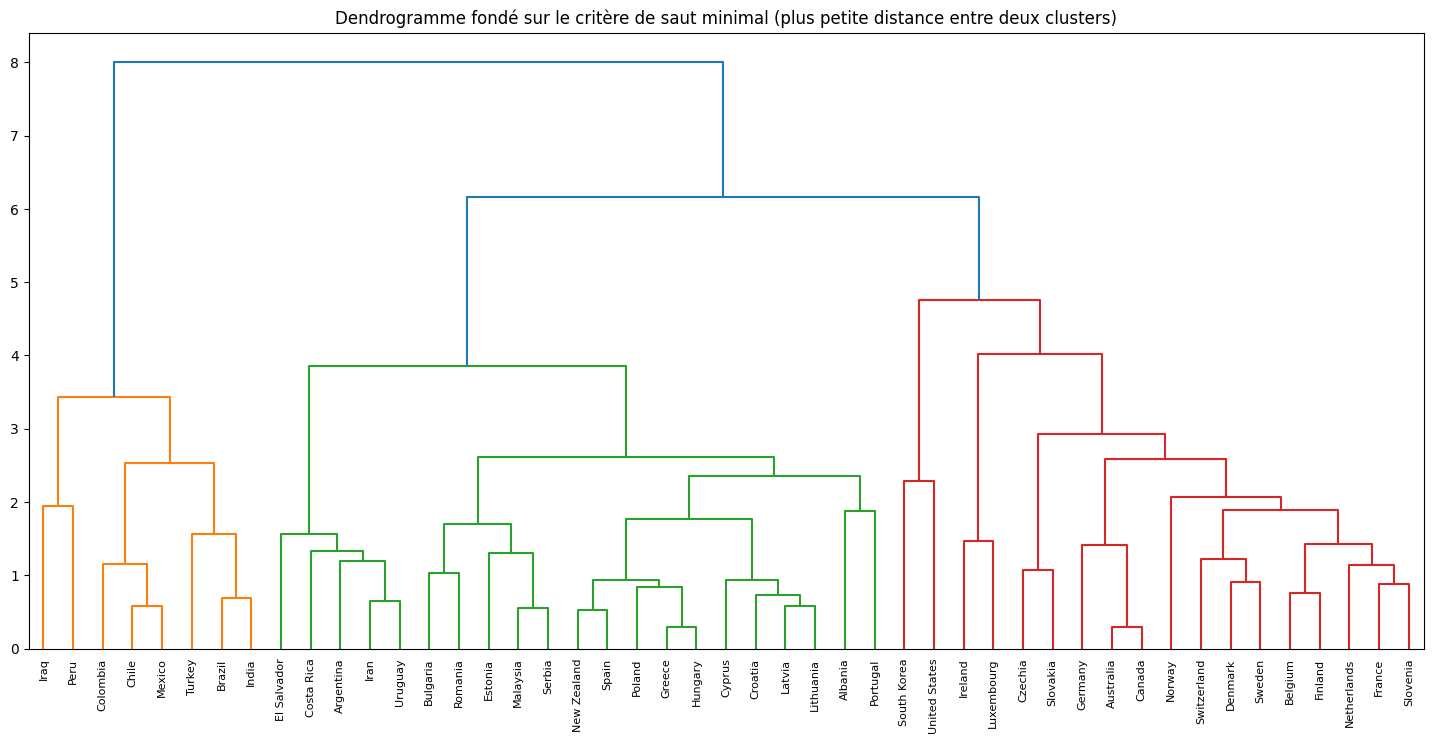

In [155]:
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(df_for_dendrogram, "complete")
plt.figure(figsize=(18, 8))
dn = dendrogram(Z, labels=df_for_dendrogram.index.tolist())
plt.title("Dendrogramme fondé sur le critère de saut minimal (plus petite distance entre deux clusters)")
plt.show()

In [156]:
# Classification du jeu de données en trois groupes par CAH
from sklearn.cluster import AgglomerativeClustering
cah=AgglomerativeClustering(n_clusters=3)
clusters=cah.fit_predict(df_for_dendrogram)
pcaed_gdf["cluster"]=clusters

Text(0.5, 1.0, 'Carte des trois clusters obtenus par CAH')

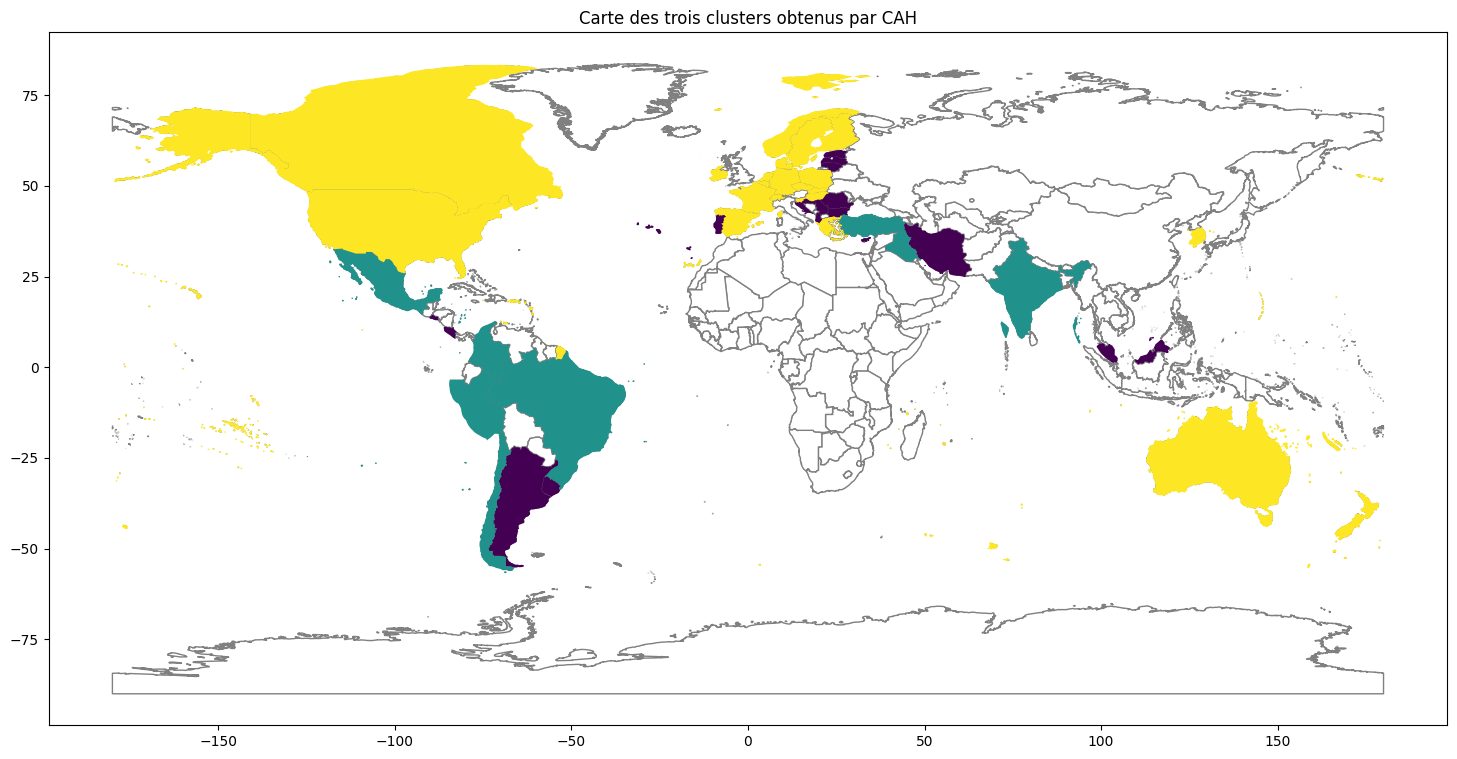

In [157]:
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
pcaed_gdf.plot(
    ax=ax,
    column="cluster",
)
ax.set_title("Carte des trois clusters obtenus par CAH")

In [158]:
import plotly.express as px
pcaed_gdf["cluster"]=pcaed_gdf["cluster"].astype("str")

fig = px.scatter(
    pcaed_gdf,
    x=0,
    y=1,
    color="cluster",
    hover_name="Entity",
    height=1000,
    width=1000,
    title="Projection des trois groupes sur les deux premières composantes principales",
    labels={
        "0":"Première Composante Principale",
        "1": "Deuxième Composante Pincipale"
    }
)

fig.update_yaxes(
    scaleanchor="x",
    scaleratio=1,
    zeroline=True,
    zerolinecolor="black",
    zerolinewidth=1
)

fig.update_xaxes(
    zeroline=True,
    zerolinecolor="black",
    zerolinewidth=1
)

fig.show(renderer="iframe")

# Régression linéaire multiple
On explique le GDP per capita en fonction des autres variables.  
On calcule le vecteur B des coefficients comme $(X^TX)^{-1}X^TY$.

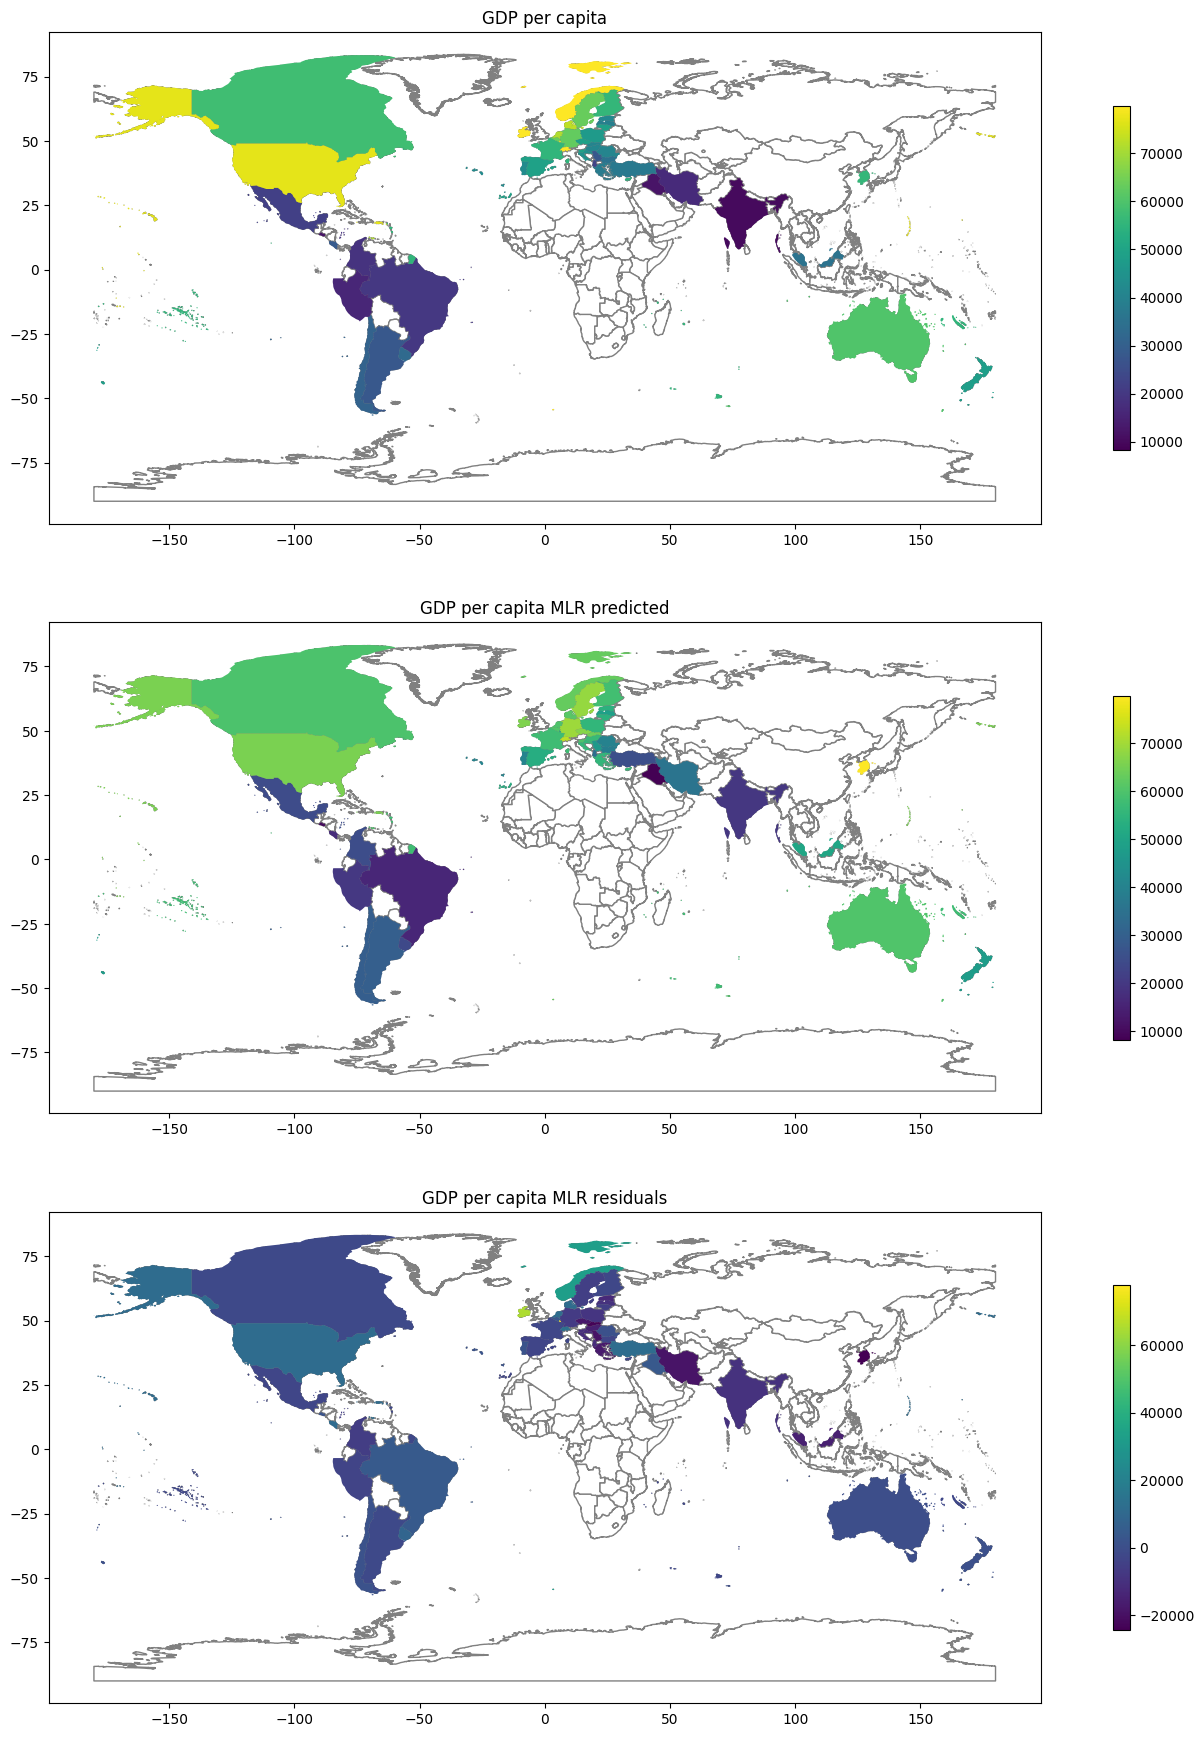

In [159]:
Y=vars_arr[:,0]
X=vars_arr.copy()
X[:,0]=1
B=np.linalg.solve(X.T@X, X.T@Y)
Y_hat=X@B
residuals=Y-Y_hat
all_vars["GDP per capita MLR predicted"]=Y_hat
all_vars["GDP per capita MLR residuals"]=residuals
width=15
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(
        width,
        width * map_relative_height*3
    )
)

for i, (ax, col) in enumerate(zip([ax1, ax2, ax3], ["GDP per capita","GDP per capita MLR predicted", "GDP per capita MLR residuals"])):
    vmin, vmax=(all_vars["GDP per capita MLR predicted"].min(), all_vars["GDP per capita MLR predicted"].max()) if i<2 else (all_vars[col].min(), all_vars[col].max())
    geo_countries.plot(
        ax=ax,
        color="white",
        edgecolor="gray"
    )

    all_vars.plot(
        ax=ax,
        column=col,
        legend=True,
        legend_kwds={"shrink": 0.7},
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(col)

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.show()

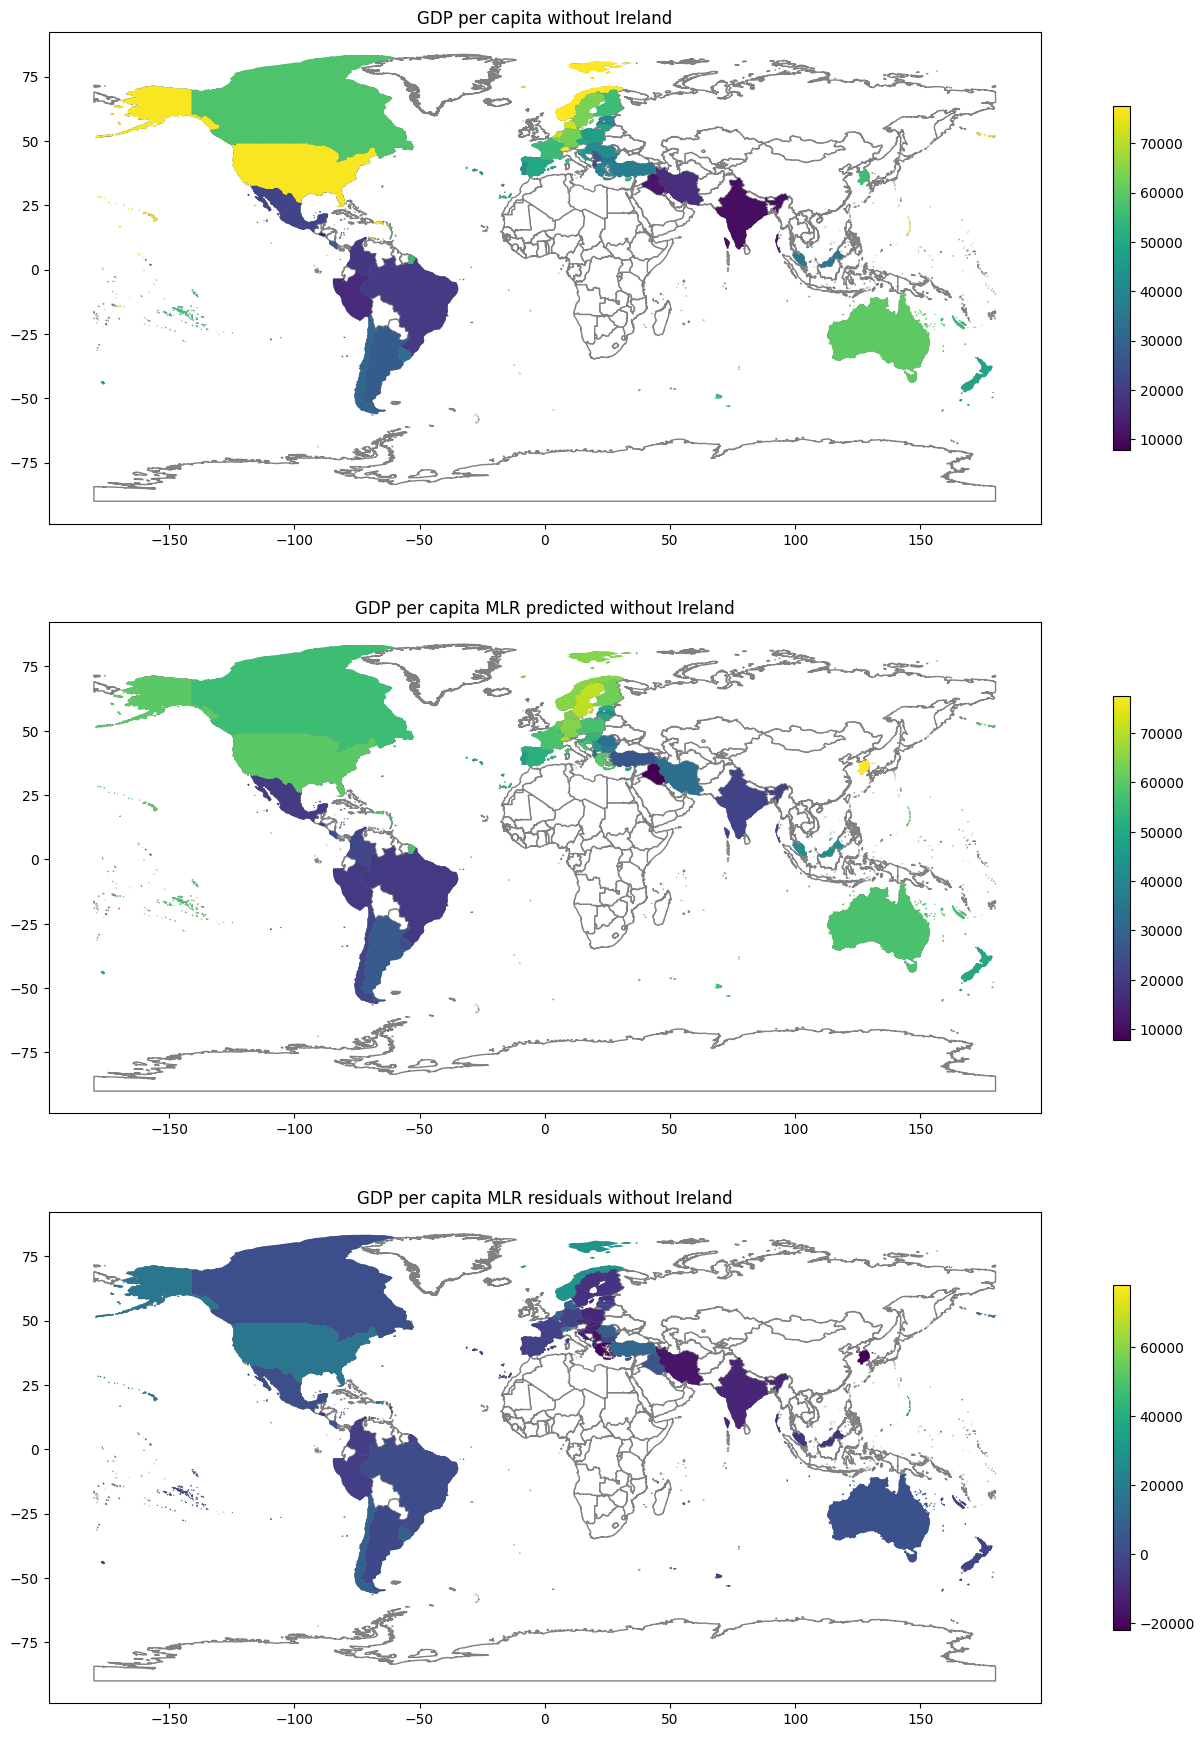

In [160]:
#version sans Irlande

no_irld=all_vars[all_vars.Entity!="Ireland"]
no_irld_arr=vars_arr[all_vars.Entity!="Ireland"]

Y_f=no_irld_arr[:,0]
X_f=no_irld_arr.copy()
X_f[:,0]=1
B=np.linalg.solve(X_f.T@X_f, X_f.T@Y_f)
Y_hat_f=X_f@B
residuals=Y_f-Y_hat_f
no_irld["GDP per capita MLR predicted"]=Y_hat_f
no_irld["GDP per capita MLR residuals"]=residuals
width=15
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(
        width,
        width * map_relative_height*3
    )
)

for i, (ax, col) in enumerate(zip([ax1, ax2, ax3], ["GDP per capita","GDP per capita MLR predicted", "GDP per capita MLR residuals"])):
    vmin, vmax=(no_irld["GDP per capita MLR predicted"].min(), no_irld["GDP per capita MLR predicted"].max()) if i<2 else (no_irld[col].min(), no_irld[col].max())
    geo_countries.plot(
        ax=ax,
        color="white",
        edgecolor="gray"
    )

    no_irld.plot(
        ax=ax,
        column=col,
        legend=True,
        legend_kwds={"shrink": 0.7},
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(col + " without Ireland")

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.show()

# auto-corrélation spatiale

## Calcul de la matrice de voisinnage par triangulation de Delaunay
on supprime également les arrêtes de plus de 3000 kilomètres et on ajoute le plus proche voisin comme voisin de chaque pays

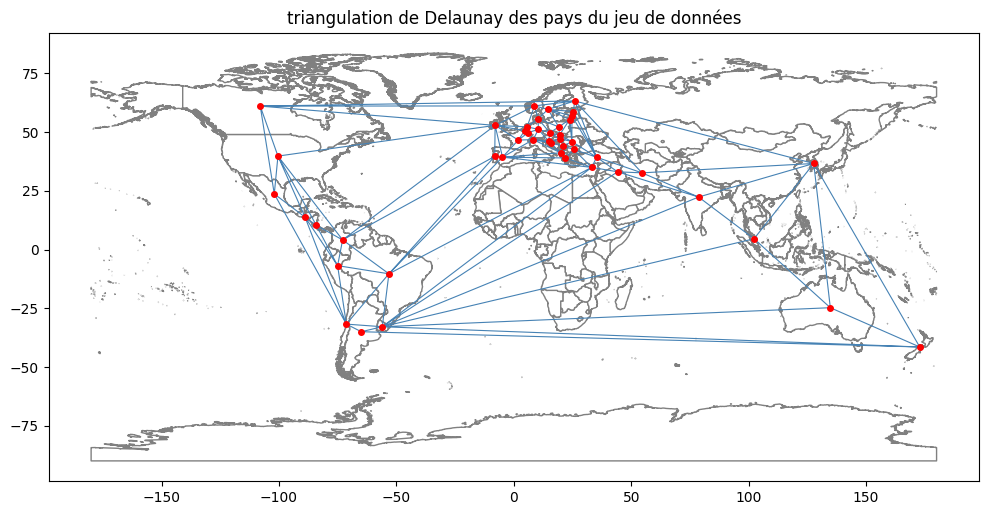

In [161]:
# Triangulation à partir des coordonnées
tri = Delaunay(all_vars[["lon", "lat"]])

# Créer la figure et tracer les pays
fig, ax = plt.subplots(figsize=(12, 10))

geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)

# Tracer les triangles
ax.triplot(
    all_vars["lon"],
    all_vars["lat"],
    tri.simplices,
    color="steelblue",
    linewidth=0.8
)

# Tracer les points
ax.plot(
    all_vars["lon"],
    all_vars["lat"],
    "o",
    color="red",
    markersize=4
)

ax.set_aspect("equal")
plt.title("triangulation de Delaunay des pays du jeu de données")
plt.show()

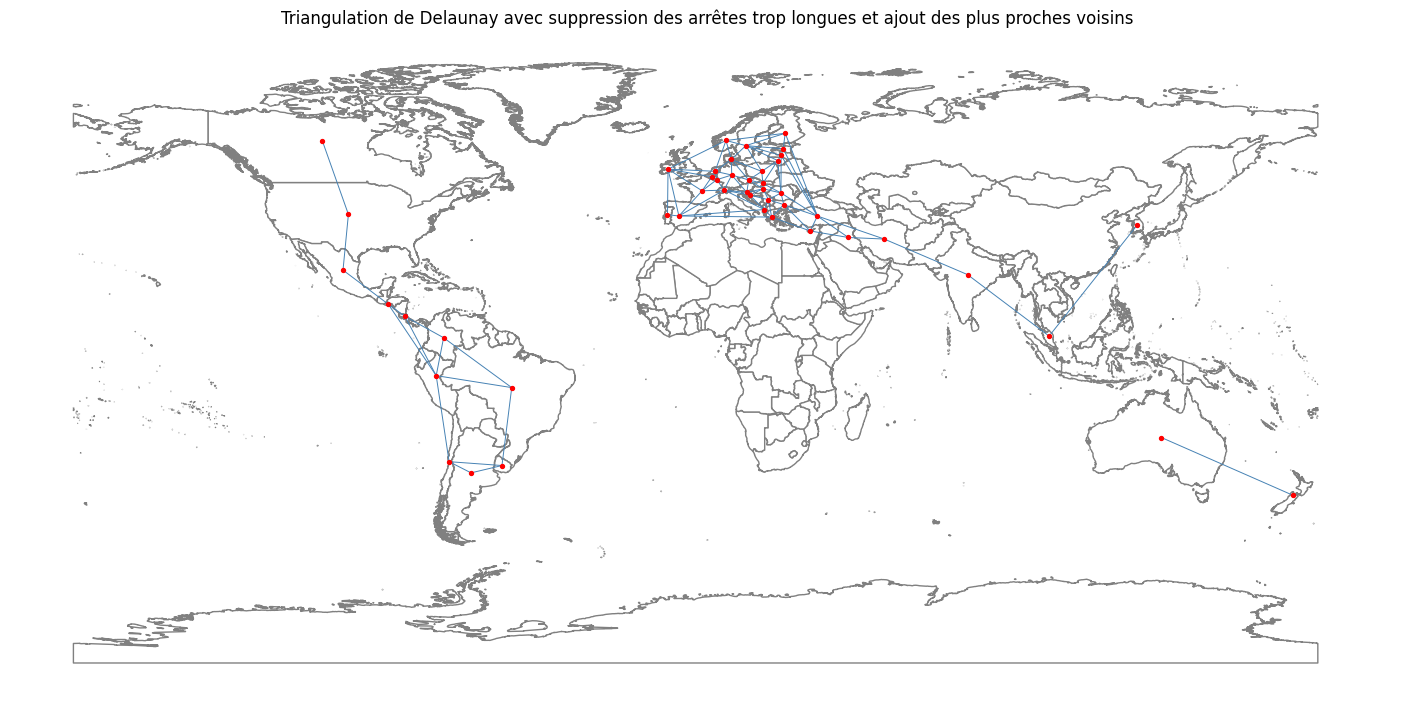

In [162]:
# suppression des arrêtes de plus de 3000 km
G = nx.Graph()
G.add_nodes_from(range(len(all_vars)))

for simplex in tri.simplices:
    for i in range(3):
        u = simplex[i]
        v = simplex[(i + 1) % 3]
        G.add_edge(u, v)


edges=np.array([edge for edge in G.edges()])
edges_filtered=edges[np.array([geodesic((all_vars.at[p1, "lat"], all_vars.at[p1, "lon"]), (all_vars.at[p2, "lat"], all_vars.at[p2, "lon"])).kilometers for p1, p2 in edges])<3000]
W=np.zeros((len(all_vars), len(all_vars)))
W[edges_filtered[:, 0], edges_filtered[:, 1]]=1
W[edges_filtered[:, 1], edges_filtered[:, 0]]=1


# ajout des plus proches voisins
xx, yy=np.meshgrid(range(len(all_vars)), range(len(all_vars)))
coords_pairs=np.stack([xx.ravel(), yy.ravel()]).T
D_mat=np.empty((len(all_vars), len(all_vars)))
for p1, p2 in coords_pairs:
    D_mat[p1, p2]=geodesic((all_vars.at[p1, "lat"], all_vars.at[p1, "lon"]), (all_vars.at[p2, "lat"], all_vars.at[p2, "lon"])).kilometers
argmins=(D_mat+np.identity(len(D_mat))*30000).argmin(axis=1)
W[range(len(W)), argmins]=1
W[argmins, range(len(W))]=1
G_f=nx.Graph()
G_f.add_nodes_from(range(len(all_vars)))
G_f.add_edges_from(edges_filtered)
G_f.add_edges_from(np.column_stack([range(len(W)), argmins]))

# carte du voisinnage
pos=all_vars[["lon", "lat"]].values.tolist()
fig, ax = plt.subplots(figsize=np.array([12, 10])*1.5)

geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)

nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

ax.set_aspect("equal")
plt.title("Triangulation de Delaunay avec suppression des arrêtes trop longues et ajout des plus proches voisins")
plt.show()

## Analyse de l'auto-corrélation

In [178]:
# Variogramme de Moran
W_n=W/W.sum(axis=1, keepdims=True)
W_n=np.nan_to_num(W_n)
Y_c=Y-Y.mean()
Y_nei=W_n@Y_c
moran_variogram_df=pd.DataFrame({"GDP per capita deviation from mean":Y_c, "neighbors GDP per capita deviation from mean":Y_nei, "country_name":all_vars.Entity})
moran_variogram_df["cadran"]=(moran_variogram_df["GDP per capita deviation from mean"]>=0).astype(int).astype(str)+(moran_variogram_df["neighbors GDP per capita deviation from mean"]>=0).astype(int).astype(str)

fig = px.scatter(
    moran_variogram_df,
    x="GDP per capita deviation from mean",
    y="neighbors GDP per capita deviation from mean",
    color="cadran",
    hover_name="country_name",
    height=1000,
    width=1000,
    title="Variogramme de Moran du PIB par habitant",
)

fig.update_yaxes(
    scaleanchor="x",
    scaleratio=1,
    zeroline=True,
    zerolinecolor="black",
    zerolinewidth=1
)

fig.update_xaxes(
    zeroline=True,
    zerolinecolor="black",
    zerolinewidth=1
)

fig.show(renderer="iframe")

In [164]:
# Morans'I
moransI=(Y_c.T@Y_nei)/(Y_c.T@Y_c)
moransIi=Y_c*Y_nei/(Y_c.var())
all_vars["GDP Moran's Ii"]=moransIi

Text(0.5, 1.0, "Moran's I local du PIB par habitant")

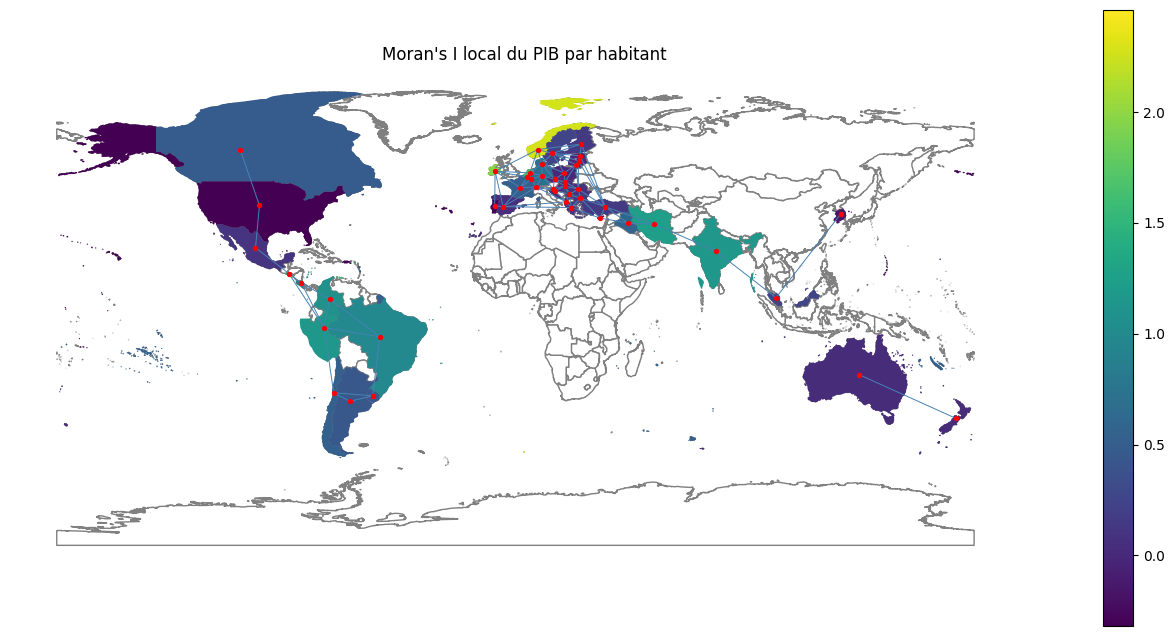

In [165]:
scale_factor=8
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
all_vars.plot(
    ax=ax,
    column="GDP Moran's Ii",
    legend=True)

nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)
ax.set_title("Moran's I local du PIB par habitant")

In [166]:
# calcul de l'ensemble des indices I locaux de Moran
all_vars["Moran's I local du PIB"]=np.round(all_vars["GDP Moran\'s Ii"], 2)
vars_c=vars_arr-vars_arr.mean(axis=0, keepdims=True)
all_vars_MoransIi=(W_n@vars_c)*vars_c/vars_c.var(axis=0, keepdims=True)
vars_names=all_vars.drop(columns=["Entity", "Code", "Year", "World region according to OWID", "geometry", "lat", "lon"]).columns[:7]
moransIi_names=[name+" Moran's Ii" for name in vars_names]
all_vars[moransIi_names]=all_vars_MoransIi

# Régression Linéaire Multiple Pondérée Géographiquement

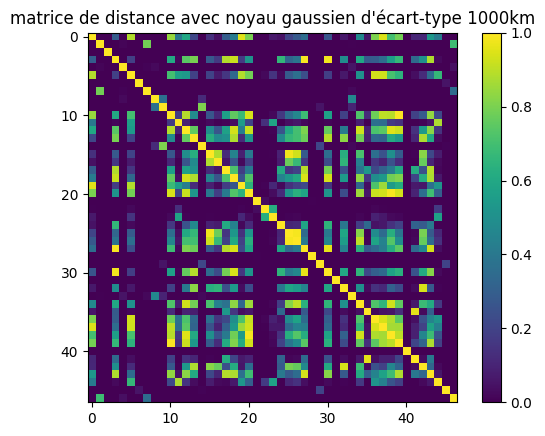

In [167]:
# matrice de distance avec noyau gaussien
h=1000 #largeur de bande/écart type de gaussienne de 1000km
W=np.exp(-((1/2)*D_mat**2)/(h**2))
plt.imshow(W)
plt.title("matrice de distance avec noyau gaussien d'écart-type 1000km")
plt.colorbar()

In [168]:
#calcul des coeficients pour chaque individu, en fonction de son voisinnage
B=np.empty_like(X)
for i in range(len(X)):
    B[i]=np.linalg.solve(X.T@(W[i][:,np.newaxis]*X), X.T@(W[i]*Y))

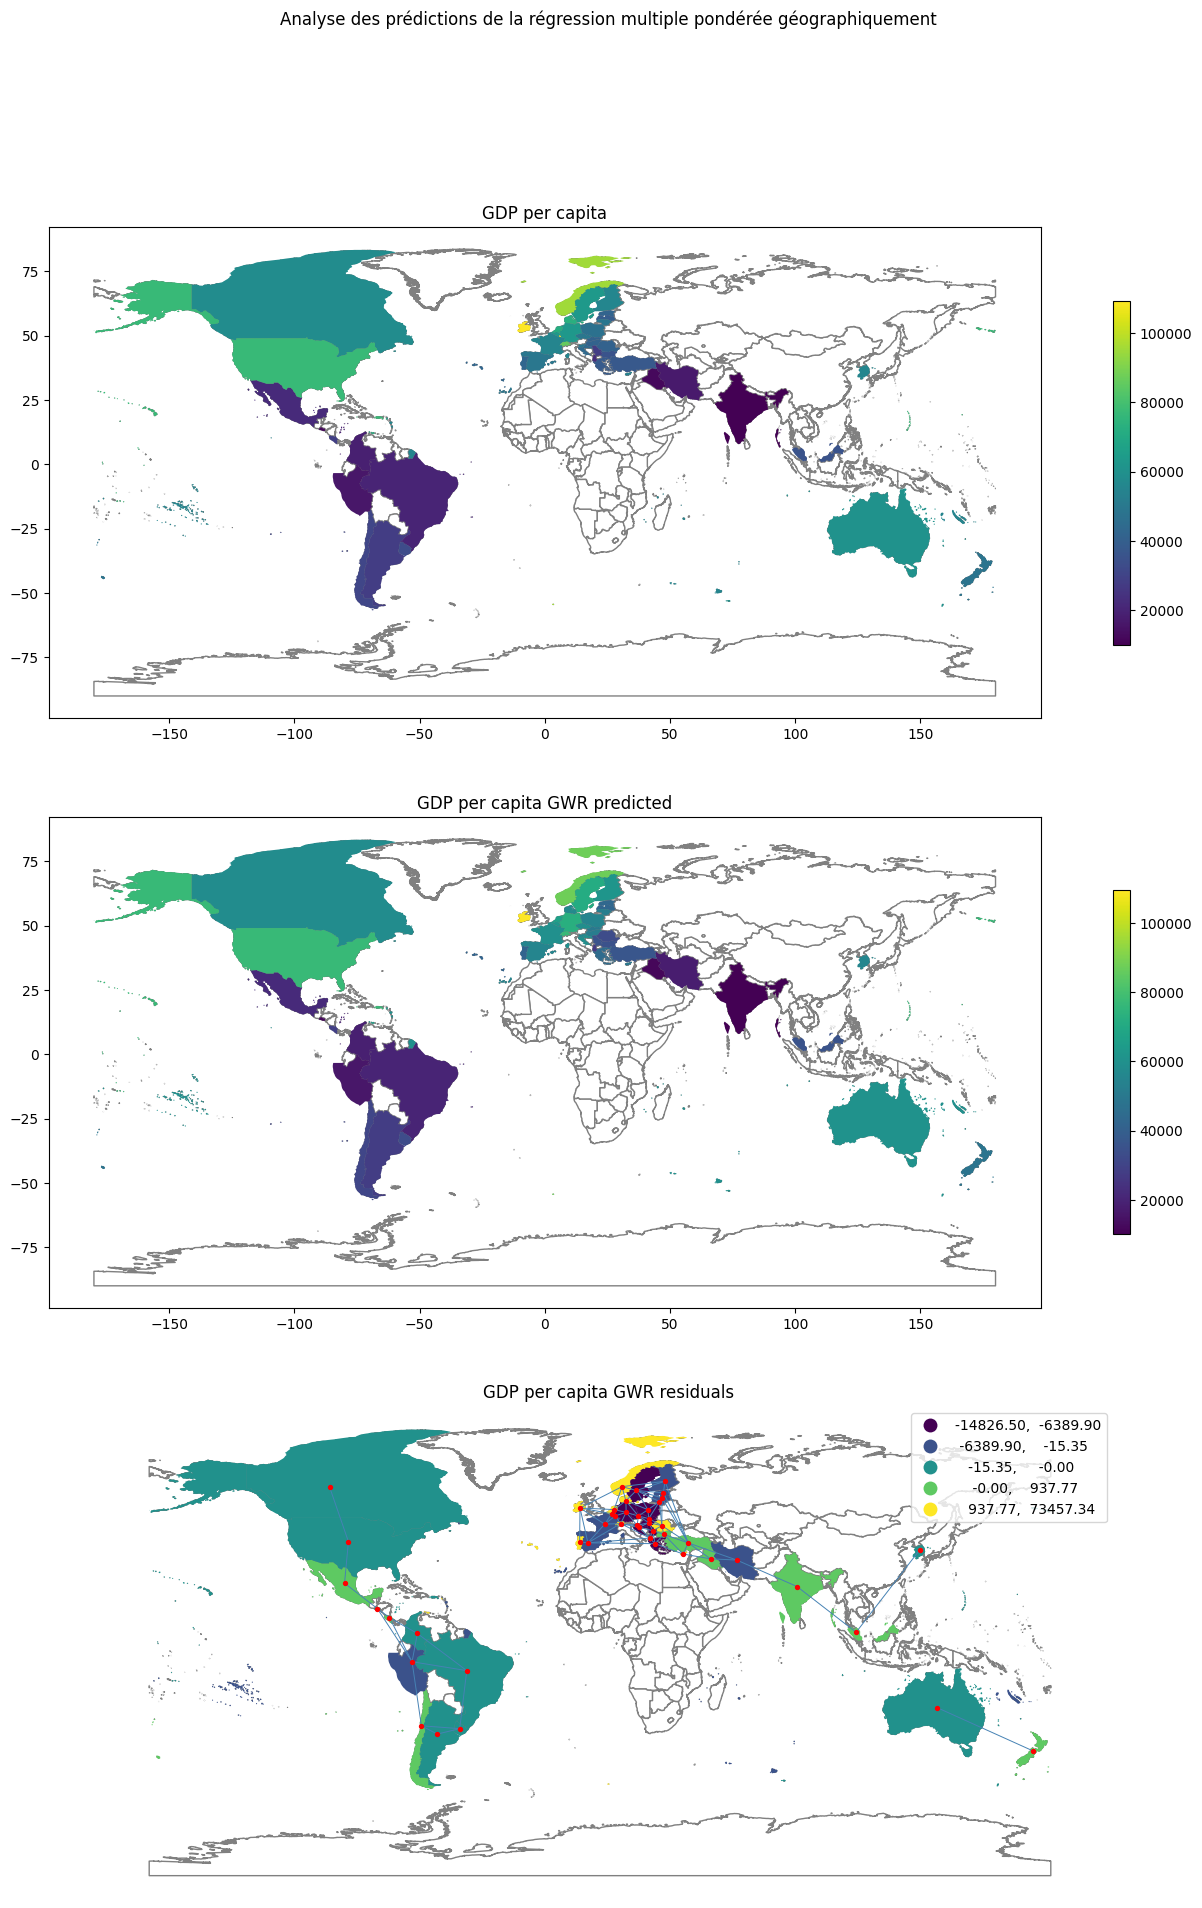

In [169]:
Y_hat=((B@X.T)*np.identity(len(X))).sum(axis=0)
residuals=Y-Y_hat
all_vars["GDP per capita GWR predicted"]=Y_hat
all_vars["GDP per capita GWR residuals"]=residuals
width=15
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(
        width,
        width * map_relative_height*3
    )
)

for i, (ax, col) in enumerate(zip([ax1, ax2], ["GDP per capita","GDP per capita GWR predicted"])):
    vmin, vmax=(all_vars["GDP per capita GWR predicted"].min(), all_vars["GDP per capita GWR predicted"].max()) if i<2 else (all_vars[col].min(), all_vars[col].max())
    geo_countries.plot(
        ax=ax,
        color="white",
        edgecolor="gray"
    )

    all_vars.plot(
        ax=ax,
        column=col,
        legend=True,
        legend_kwds={"shrink": 0.7},
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(col)

geo_countries.plot(
        ax=ax3,
        color="white",
        edgecolor="gray"
    )

all_vars.plot(
    ax=ax3,
    column="GDP per capita GWR residuals",
    legend=True,
    scheme="quantiles"
)

nx.draw(
    G_f,
    pos=pos,
    ax=ax3,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

ax3.set_title("GDP per capita GWR residuals")

fig.subplots_adjust(left=0.02, right=0.98, wspace=0.02)
plt.suptitle("Analyse des prédictions de la régression multiple pondérée géographiquement")
plt.show()

## Cartographies des coeficients

In [170]:
coefs_names=[name+" GWR coef" for name in vars_names]
coefs_names[0]="ordonnée à l'origine"
coefs_gdf=all_vars[["geometry", "Entity"]].join(pd.DataFrame(B, columns=coefs_names))
coef_it=iter(coefs_names)

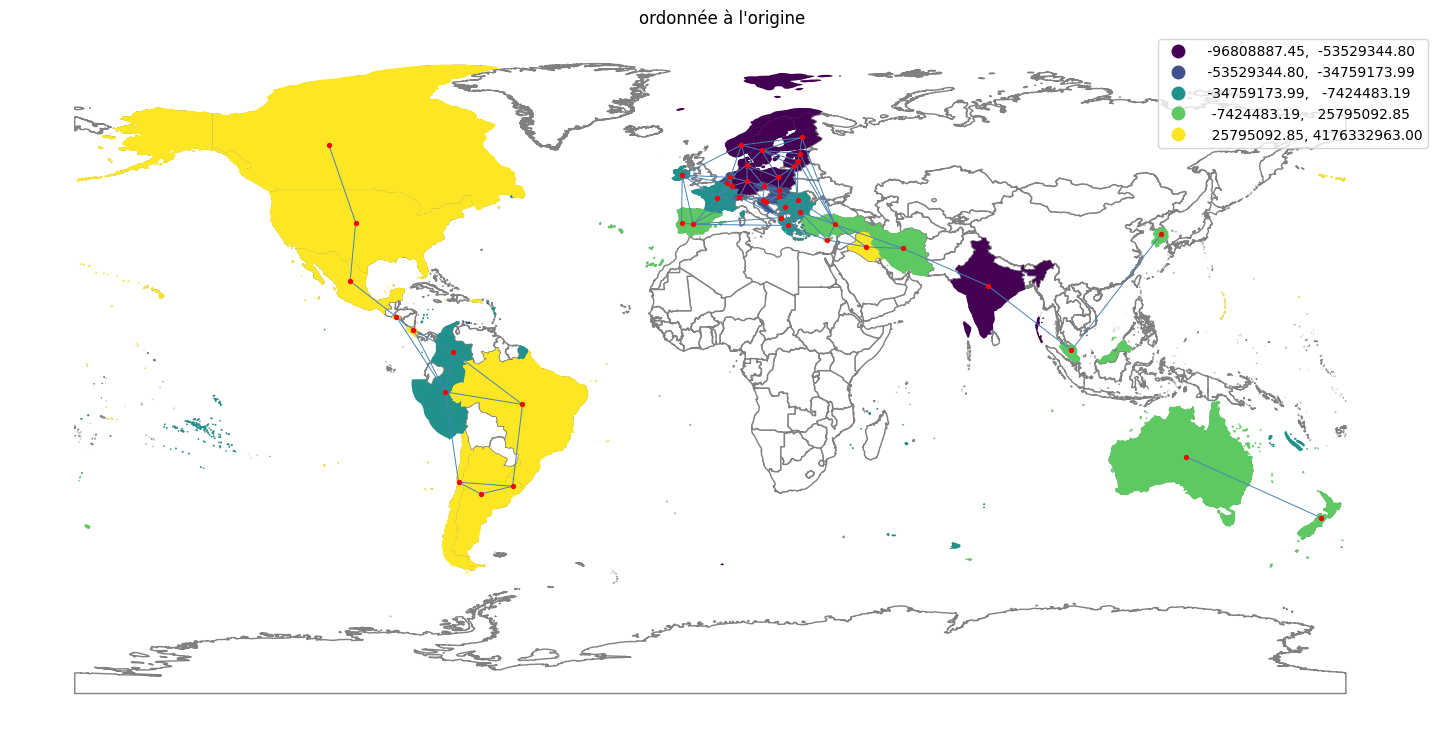

In [171]:
col=next(coef_it)
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
coefs_gdf.plot(
    ax=ax,
    column=col,
    legend=True,
    scheme="quantiles"
)
ax.set_title(col)

nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

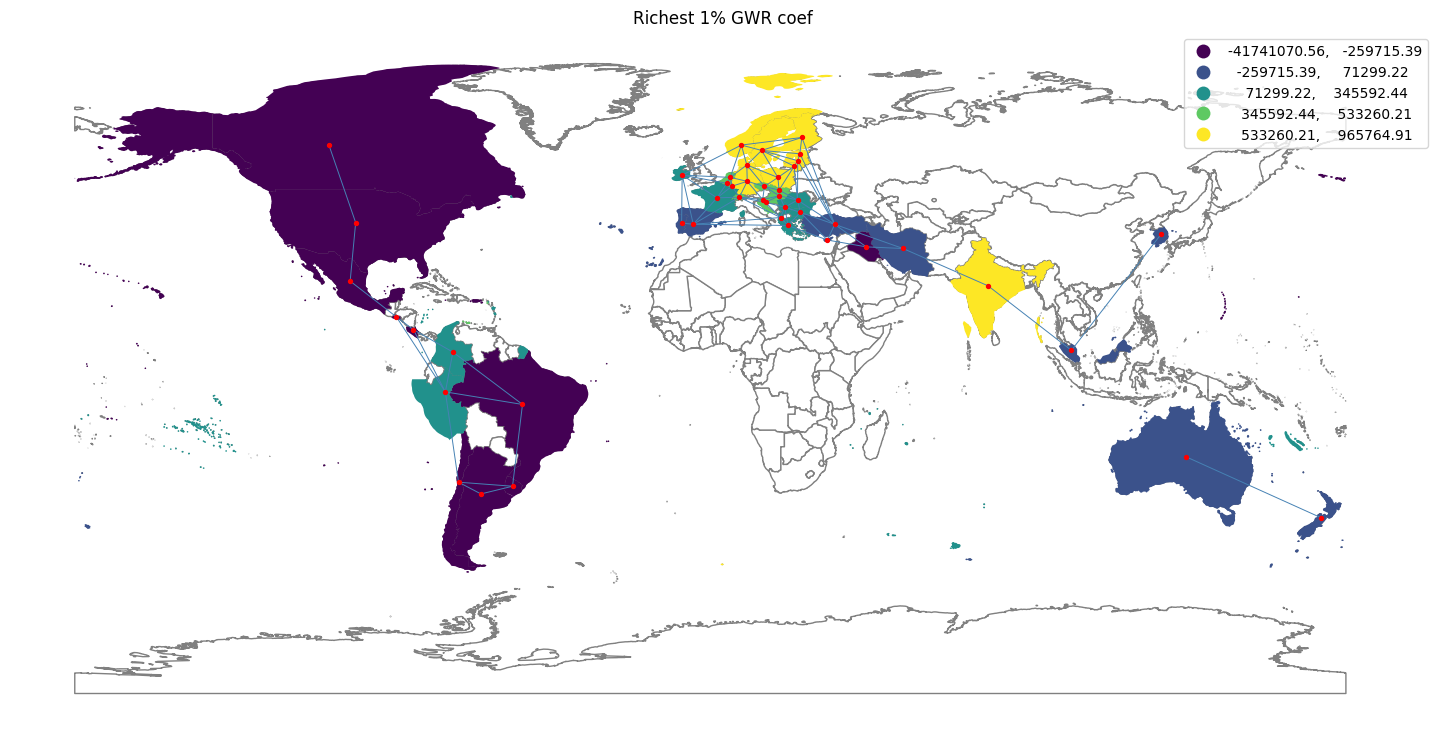

In [172]:
col=next(coef_it)
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
coefs_gdf.plot(
    ax=ax,
    column=col,
    legend=True,
    scheme="quantiles"
)
ax.set_title(col)
nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

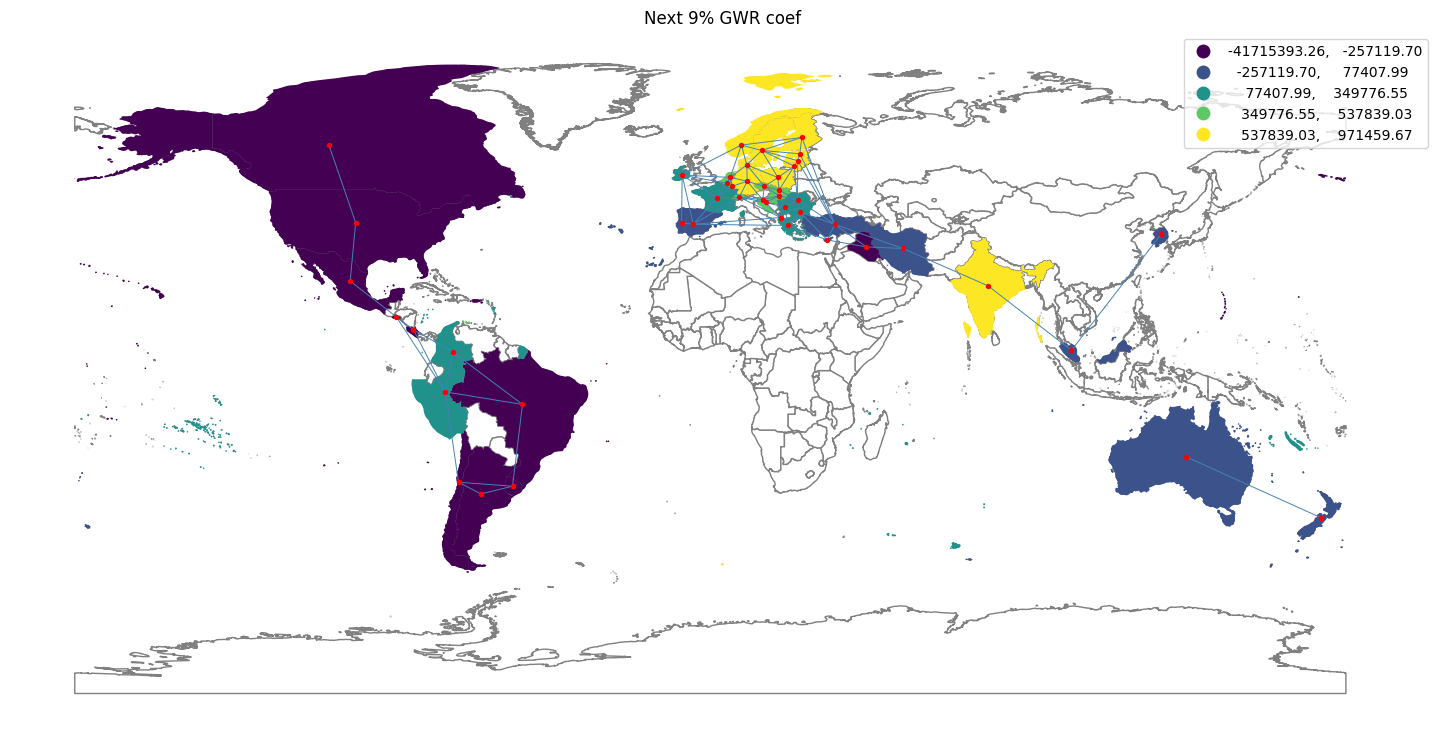

In [173]:
col=next(coef_it)
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
coefs_gdf.plot(
    ax=ax,
    column=col,
    legend=True,
    scheme="quantiles"
)
ax.set_title(col)
nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

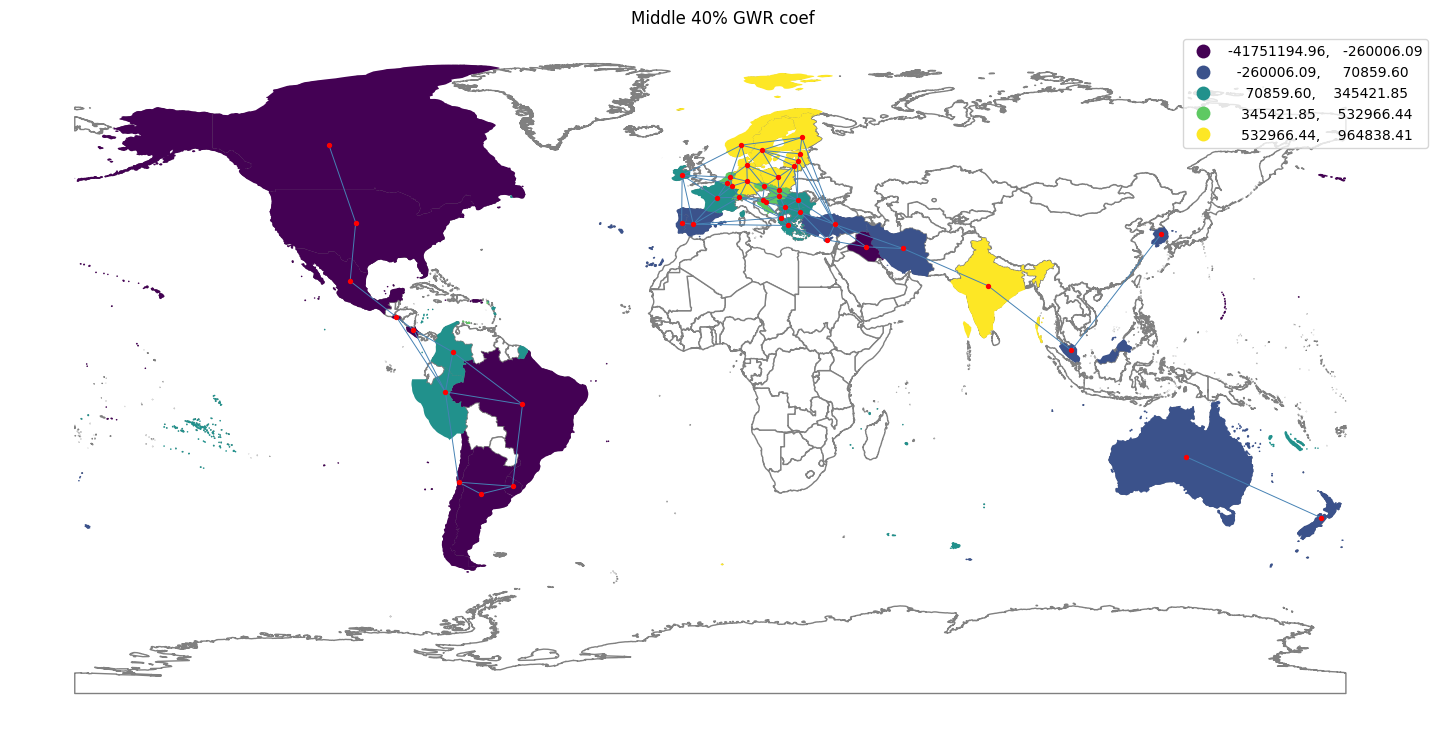

In [174]:
col=next(coef_it)
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
coefs_gdf.plot(
    ax=ax,
    column=col,
    legend=True,
    scheme="quantiles"
)
ax.set_title(col)
nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

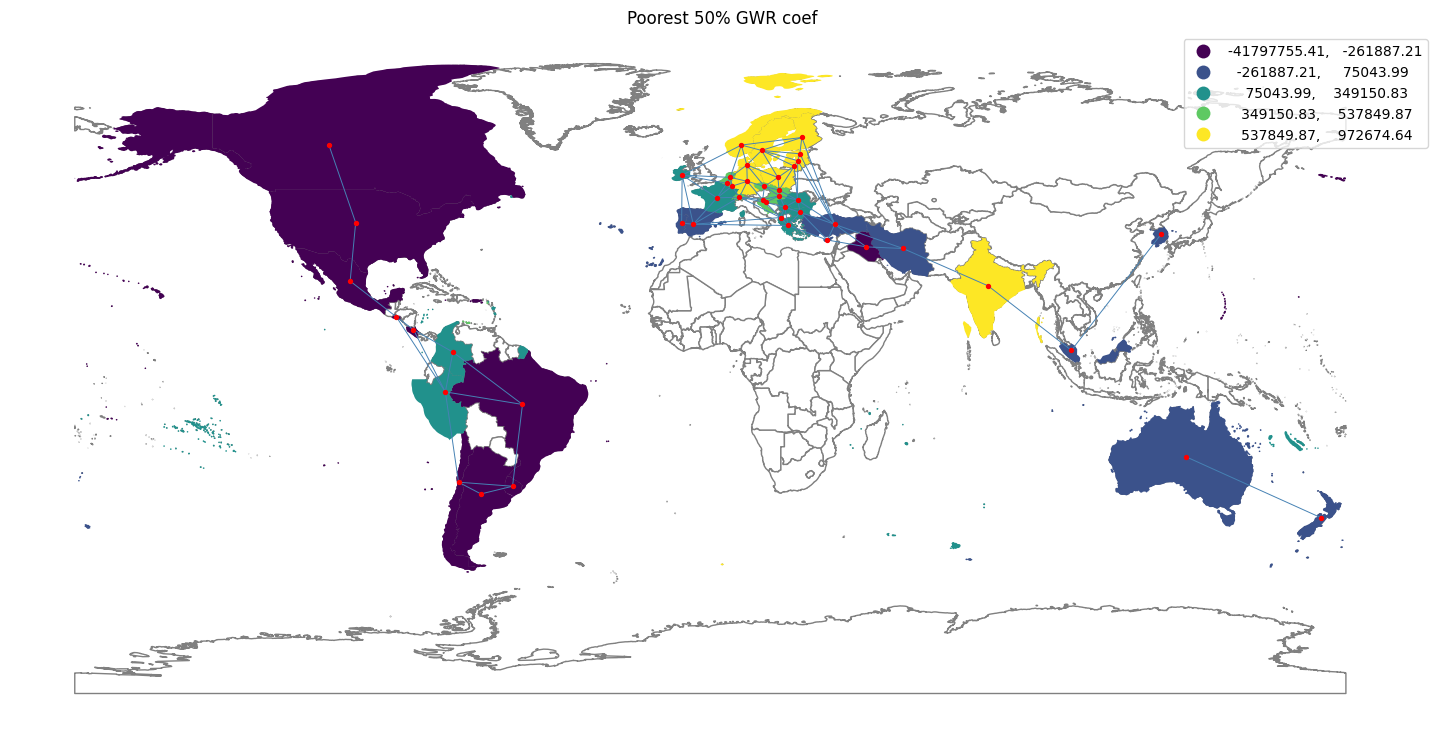

In [175]:
col=next(coef_it)
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
coefs_gdf.plot(
    ax=ax,
    column=col,
    legend=True,
    scheme="quantiles"
)
ax.set_title(col)
nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

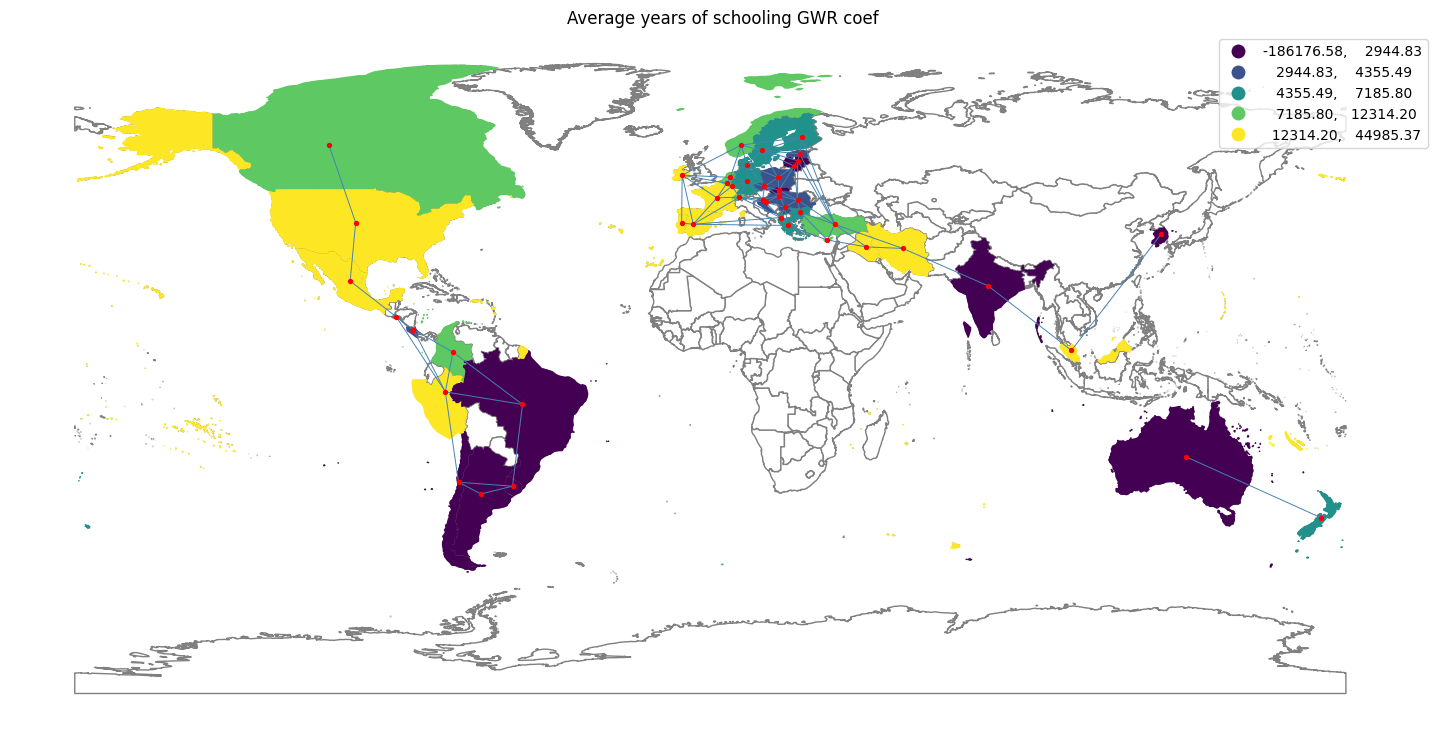

In [176]:
col=next(coef_it)
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
coefs_gdf.plot(
    ax=ax,
    column=col,
    legend=True,
    scheme="quantiles"
)
ax.set_title(col)
nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)

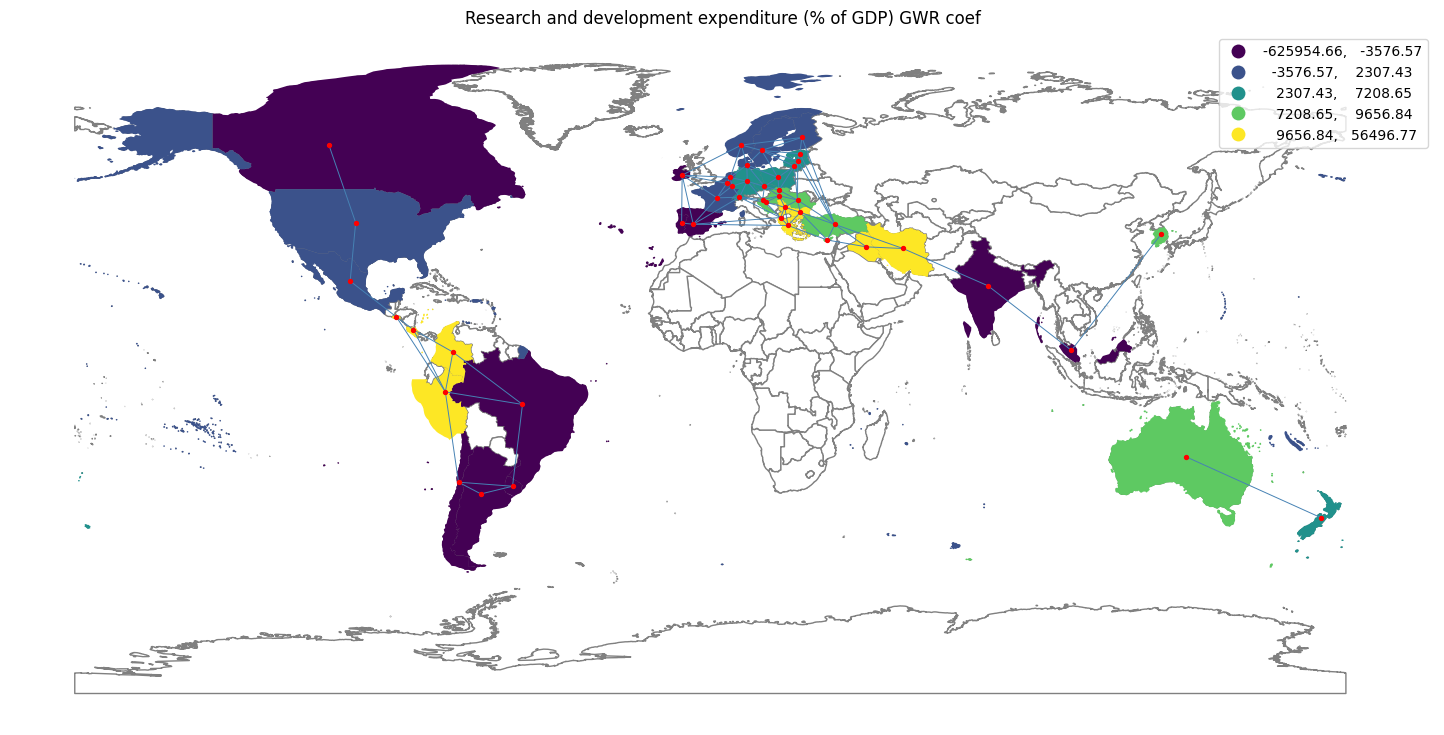

In [177]:
col=next(coef_it)
scale_factor=9
fig, ax=plt.subplots(figsize=(scale_factor*map_relative_width,scale_factor))
geo_countries.plot(
    ax=ax,
    color="white",
    edgecolor="gray"
)
coefs_gdf.plot(
    ax=ax,
    column=col,
    legend=True,
    scheme="quantiles"
)
ax.set_title(col)
nx.draw(
    G_f,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="red",
    edge_color="steelblue",
    width=0.7,
    with_labels=False
)